# Parte práctica de la Semana 3 · Fase 4

## Catálogo de visualización: qué hace cada gráfico y cuándo usarlo

---

Este cuaderno recorre los tipos de gráfico del ecosistema científico de Python. Para cada
uno responde cuatro preguntas: qué es, para qué sirve, qué comunica y cuándo no
corresponde usarlo.

Los ejemplos son deliberadamente variados. Cada familia de gráficos se demuestra con el
tipo de datos que la hace natural, de modo que al buscar el gráfico para su proyecto
puedan reconocer el caso análogo.

### Por qué importa elegir bien

Un gráfico traduce números a una propiedad visual: posición, longitud, ángulo, área,
color. **Cada una de esas propiedades se percibe con una precisión distinta**, y esa
diferencia decide qué gráfico comunica y cuál solo decora.

Toda la primera parte trata sobre eso, porque es lo que permite decidir sin memorizar
reglas.

### Recorrido

| Parte | Contenido |
|---|---|
| I | Cómo el ojo lee un gráfico |
| II | Comparar categorías |
| III | Ver distribuciones |
| IV | Examinar relaciones |
| V | Seguir una evolución |
| VI | Mostrar composición |
| VII | Panoramas y matrices |
| VIII | Paneles y anotación |
| IX | Cómo elegir, en resumen |
| X | Errores que distorsionan |
| XI | Terminar y exportar la figura |
| XII | Su turno |

## Preparación del entorno

In [ ]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

SEMILLA = 42
rng = np.random.default_rng(SEMILLA)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 12.5,
    "axes.titleweight": "bold",
    "axes.labelsize": 10.5,
    "legend.frameon": False,
    "font.size": 10,
})

# Paleta con función: color donde está el hallazgo, gris para el contexto
DESTACADO = "#AC212E"
NEUTRO = "#9FB6C8"
CONTRASTE = "#06304A"

print("NumPy", np.__version__, "| pandas", pd.__version__,
      "| Matplotlib", plt.matplotlib.__version__, "| seaborn", sns.__version__)

NumPy 2.4.4 | pandas 3.0.2 | Matplotlib 3.10.8 | seaborn 0.13.2


## Los conjuntos de ejemplo

Cuatro conjuntos sintéticos, cada uno pensado para una familia distinta de gráficos.
Ninguno corresponde a un proyecto en particular: son casos genéricos que ustedes pueden
reconocer en el suyo.

| Conjunto | Qué contiene | Qué familia ilustra |
|---|---|---|
| `ventas` | Unidades e ingreso por región, categoría, canal y mes | Comparación y composición |
| `alumnos` | Notas, horas de estudio, edad y área | Distribución y relación |
| `clima` | Temperatura y humedad diaria durante dos años | Evolución |
| `encuesta` | Satisfacción en escala de cinco niveles por grupo | Ordinales y matrices |

In [ ]:
# ---------------------------------------------------------------- ventas ---
regiones = ["Norte", "Centro", "Sur", "Austral"]
categorias = ["Bebidas", "Lacteos", "Abarrotes", "Limpieza", "Congelados"]
meses = pd.date_range("2024-01-01", periods=12, freq="MS")

filas = []
peso_region = {"Norte": 0.9, "Centro": 1.6, "Sur": 1.1, "Austral": 0.5}
peso_cat = {"Bebidas": 1.4, "Lacteos": 1.2, "Abarrotes": 1.0, "Limpieza": 0.8, "Congelados": 0.6}
for region in regiones:
    for categoria in categorias:
        for mes in meses:
            estacional = 1 + 0.25 * np.sin((mes.month - 1) / 12 * 2 * np.pi)
            unidades = rng.poisson(420 * peso_region[region] * peso_cat[categoria] * estacional)
            filas.append({"region": region, "categoria": categoria, "mes": mes,
                          "canal": rng.choice(["Presencial", "En linea"], p=[0.68, 0.32]),
                          "unidades": unidades,
                          "ingreso": round(unidades * rng.normal(2350, 260), 0)})
ventas = pd.DataFrame(filas)

# ---------------------------------------------------------------- alumnos ---
n = 1200
areas = ["Ingenieria", "Salud", "Educacion", "Artes"]
alumnos = pd.DataFrame({
    "area": rng.choice(areas, n, p=[0.36, 0.28, 0.22, 0.14]),
    "jornada": rng.choice(["Diurna", "Vespertina"], n, p=[0.64, 0.36]),
    "edad": np.round(rng.gamma(9, 2.6, n) + 17, 0).clip(17, 55),
})
base = {"Ingenieria": 4.6, "Salud": 5.1, "Educacion": 5.3, "Artes": 5.0}
alumnos["horas_estudio"] = np.round(rng.gamma(4, 2.1, n), 1).clip(0.5, 30)
alumnos["nota"] = np.round(
    [base[a] + 0.055 * h + rng.normal(0, 0.55)
     for a, h in zip(alumnos["area"], alumnos["horas_estudio"])], 1).clip(1.0, 7.0)
alumnos["aprobado"] = (alumnos["nota"] >= 4.0).astype(int)

# ------------------------------------------------------------------ clima ---
dias = pd.date_range("2023-01-01", "2024-12-31", freq="D")
estacion = np.sin((dias.dayofyear.to_numpy() - 80) / 365 * 2 * np.pi)
clima = pd.DataFrame({
    "fecha": dias,
    "temperatura": np.round(16 + 7 * estacion + rng.normal(0, 1.8, len(dias)), 1),
    "humedad": np.round(70 - 12 * estacion + rng.normal(0, 6, len(dias)), 0).clip(20, 100),
    "ciudad": "Ciudad A",
})
clima["anio"] = clima["fecha"].dt.year
clima["mes_nombre"] = clima["fecha"].dt.month

# --------------------------------------------------------------- encuesta ---
NIVELES = ["Muy malo", "Malo", "Regular", "Bueno", "Muy bueno"]
m = 800
grupo = rng.choice(["Servicio A", "Servicio B", "Servicio C"], m, p=[0.4, 0.35, 0.25])
sesgo = {"Servicio A": 0.6, "Servicio B": 0.0, "Servicio C": -0.5}
puntaje = np.clip(np.round(rng.normal(3.2, 1.0, m) + [sesgo[g] for g in grupo]), 1, 5).astype(int)
encuesta = pd.DataFrame({
    "grupo": grupo,
    "satisfaccion": pd.Categorical([NIVELES[p - 1] for p in puntaje],
                                   categories=NIVELES, ordered=True),
    "puntaje": puntaje,
    "edad": np.round(rng.normal(41, 13, m), 0).clip(18, 80),
})

for nombre, d in [("ventas", ventas), ("alumnos", alumnos), ("clima", clima), ("encuesta", encuesta)]:
    print(f"{nombre:10} {d.shape[0]:>6} filas x {d.shape[1]} columnas")

ventas        240 filas x 6 columnas
alumnos      1200 filas x 6 columnas
clima         731 filas x 6 columnas
encuesta      800 filas x 4 columnas


---
# I. Cómo el ojo lee un gráfico

Antes del catálogo conviene entender el criterio que permite decidir. Un gráfico codifica
un número en una propiedad visual, y esas propiedades **no se perciben con la misma
precisión**.

## La jerarquía de precisión

De mayor a menor precisión al estimar cantidades:

| Orden | Canal | Gráficos que lo usan |
|---|---|---|
| 1 | Posición sobre una escala común | Dispersión, líneas, puntos |
| 2 | Posición sobre escalas no alineadas | Paneles múltiples |
| 3 | Longitud | Barras |
| 4 | Ángulo o pendiente | Circular |
| 5 | Área | Burbujas, radar |
| 6 | Intensidad de color | Mapas de calor |

De ahí sale casi todo lo demás. Veámoslo con los mismos datos codificados de tres formas.

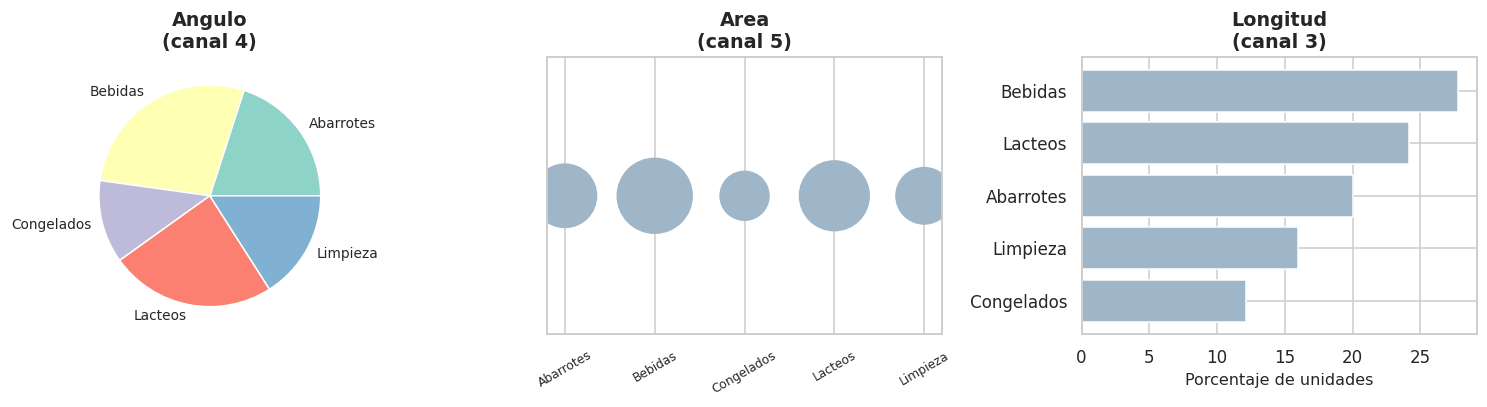

Los tres muestran exactamente los mismos porcentajes:
categoria
Bebidas       27.8
Lacteos       24.2
Abarrotes     20.0
Limpieza      15.9
Congelados    12.1


In [ ]:
participacion = ventas.groupby("categoria", observed=True)["unidades"].sum()
participacion = participacion / participacion.sum() * 100

fig, ejes = plt.subplots(1, 3, figsize=(14, 3.8))

# Canal 4: ángulo
ejes[0].pie(participacion.values, labels=participacion.index,
            colors=sns.color_palette("Set3", len(participacion)), textprops={"fontsize": 9})
ejes[0].set_title("Angulo\n(canal 4)")

# Canal 5: área
tam = participacion.values
ejes[1].scatter(range(len(tam)), [1] * len(tam), s=tam * 90, color=NEUTRO, edgecolors="none")
ejes[1].set_xticks(range(len(tam)), participacion.index, rotation=30, fontsize=8)
ejes[1].set_yticks([]); ejes[1].set_ylim(0.5, 1.5)
ejes[1].set_title("Area\n(canal 5)")

# Canal 3: longitud
orden = participacion.sort_values()
ejes[2].barh(orden.index, orden.values, color=NEUTRO)
ejes[2].set_title("Longitud\n(canal 3)")
ejes[2].set_xlabel("Porcentaje de unidades")

plt.tight_layout()
plt.show()

print("Los tres muestran exactamente los mismos porcentajes:")
print(participacion.round(1).sort_values(ascending=False).to_string())

**Intenten ordenar las cinco categorías en cada uno.** En el de longitud se ve sin
esfuerzo. En el de ángulo hay que comparar sectores parecidos. En el de área la tarea es
aún más difícil, porque el ojo subestima sistemáticamente las diferencias de superficie.

Los tres gráficos son correctos en lo técnico. Solo uno comunica.

**La regla que se deriva:** cuando exista la opción, prefieran el canal más alto de la
jerarquía. Casi siempre eso significa barras o posición en un eje.

---
# II. Comparar categorías

La familia más usada y la más útil. Responde preguntas del tipo cuánto tiene cada grupo,
cuál tiene más, cuánta es la diferencia.

### 2.1 Barras verticales

| | |
|---|---|
| **Qué es** | Una barra por categoría, cuya altura codifica la magnitud |
| **Para qué sirve** | Comparar una medida entre pocos grupos, hasta seis o siete |
| **Qué comunica** | Cuál grupo tiene más y de qué tamaño es la diferencia |
| **Cuándo no usarlo** | Con muchas categorías o etiquetas largas: usen barras horizontales |

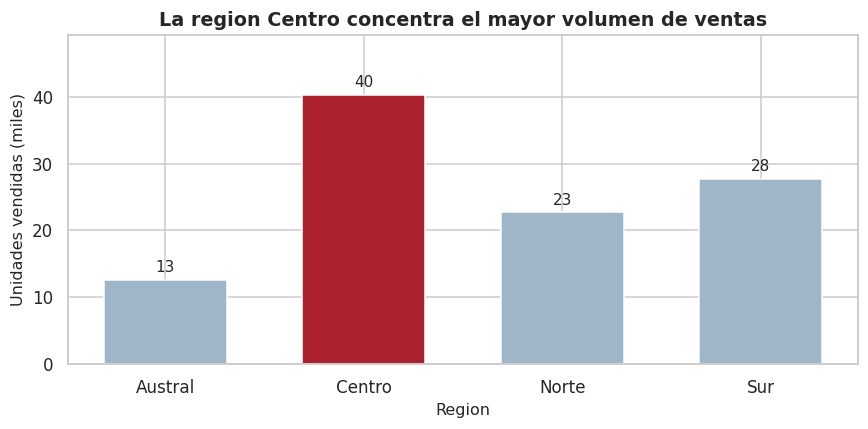

In [ ]:
por_region = ventas.groupby("region", observed=True)["unidades"].sum() / 1000

fig, eje = plt.subplots(figsize=(8, 4))
colores = [DESTACADO if v == por_region.max() else NEUTRO for v in por_region]
barras = eje.bar(por_region.index, por_region.values, color=colores, width=0.62)
eje.bar_label(barras, fmt="%.0f", padding=3)

eje.set_title("La region Centro concentra el mayor volumen de ventas")
eje.set_xlabel("Region"); eje.set_ylabel("Unidades vendidas (miles)")
eje.set_ylim(0, por_region.max() * 1.22)
plt.tight_layout(); plt.show()

**Tres decisiones que se ven en el código.** El eje parte en cero, porque en barras el
largo codifica la magnitud. Los valores van sobre las barras, así el lector no estima
contra el eje. Y el color señala una sola barra, la del hallazgo.

### 2.2 Barras horizontales

| | |
|---|---|
| **Qué es** | Lo mismo, con las barras tendidas |
| **Para qué sirve** | Comparar cuando hay muchas categorías o las etiquetas son largas |
| **Qué comunica** | El orden entre categorías, legible de un vistazo |
| **Cuándo no usarlo** | Cuando el eje horizontal representa tiempo: ahí corresponde vertical o líneas |

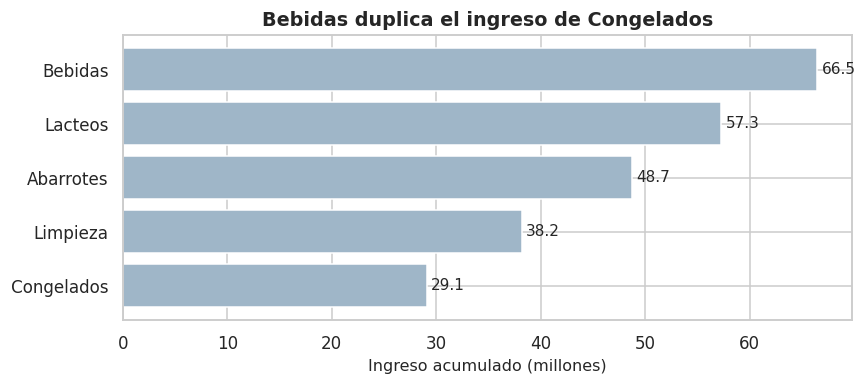

In [ ]:
por_categoria = (ventas.groupby("categoria", observed=True)["ingreso"].sum()
                 .div(1e6).sort_values())

fig, eje = plt.subplots(figsize=(8, 3.6))
barras = eje.barh(por_categoria.index, por_categoria.values, color=NEUTRO)
eje.bar_label(barras, fmt="%.1f", padding=3)
eje.set_title("Bebidas duplica el ingreso de Congelados")
eje.set_xlabel("Ingreso acumulado (millones)"); eje.set_ylabel("")
plt.tight_layout(); plt.show()

**Ordenar es parte del diseño.** Una lista de categorías sin orden obliga al lector a
buscar. Con `sort_values()` el gráfico entrega el ranking sin pedir esfuerzo.

### 2.3 Barras agrupadas

| | |
|---|---|
| **Qué es** | Varias barras por categoría, una por cada nivel de una segunda variable |
| **Para qué sirve** | Comparar dos o tres series entre las mismas categorías |
| **Qué comunica** | Si la diferencia entre series se mantiene o se invierte según la categoría |
| **Cuándo no usarlo** | Con más de tres series: las barras se adelgazan y la comparación se pierde |

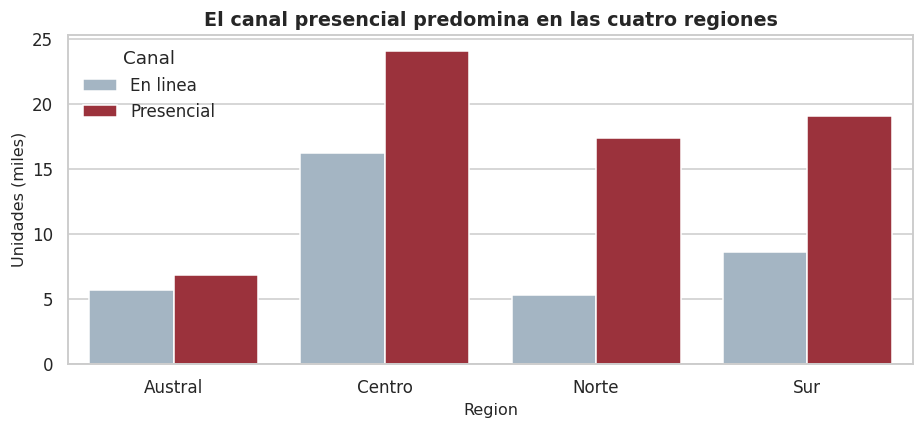

In [ ]:
tabla = (ventas.groupby(["region", "canal"], observed=True)["unidades"]
         .sum().div(1000).reset_index())

fig, eje = plt.subplots(figsize=(8.5, 4))
sns.barplot(data=tabla, x="region", y="unidades", hue="canal",
            palette=[NEUTRO, DESTACADO], ax=eje)
eje.legend(title="Canal")
eje.set_title("El canal presencial predomina en las cuatro regiones")
eje.set_xlabel("Region"); eje.set_ylabel("Unidades (miles)")
plt.tight_layout(); plt.show()

### 2.4 Gráfico de paletas

| | |
|---|---|
| **Qué es** | Una línea fina terminada en un punto, en lugar de una barra |
| **Para qué sirve** | Comparar muchas categorías sin saturar la figura de tinta |
| **Qué comunica** | Lo mismo que las barras, con menos peso visual |
| **Cuándo no usarlo** | Cuando las diferencias son pequeñas: la barra ayuda más a compararlas |

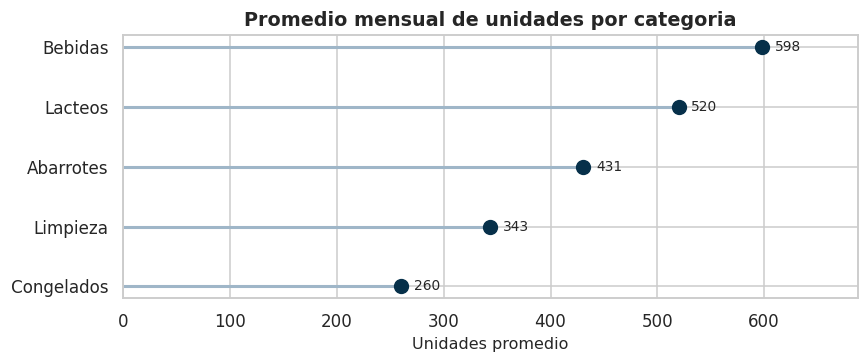

In [ ]:
promedio = (ventas.groupby("categoria", observed=True)["unidades"]
            .mean().sort_values())

fig, eje = plt.subplots(figsize=(8, 3.4))
eje.hlines(y=promedio.index, xmin=0, xmax=promedio.values, color=NEUTRO, linewidth=2)
eje.plot(promedio.values, promedio.index, "o", markersize=9, color=CONTRASTE)
for cat, valor in promedio.items():
    eje.text(valor + 12, cat, f"{valor:.0f}", va="center", fontsize=9)

eje.set_title("Promedio mensual de unidades por categoria")
eje.set_xlabel("Unidades promedio"); eje.set_ylabel("")
eje.set_xlim(0, promedio.max() * 1.15)
plt.tight_layout(); plt.show()

**Es la versión económica de las barras.** Aplica el principio de razón entre datos y
tinta: comunica lo mismo dibujando mucho menos. Conviene cuando hay diez o más
categorías.

### 2.5 Barras divergentes

| | |
|---|---|
| **Qué es** | Barras que se extienden a ambos lados de un eje central |
| **Para qué sirve** | Mostrar desviaciones respecto de una referencia: media, meta, período anterior |
| **Qué comunica** | Quién está por sobre y quién por debajo, y cuánto |
| **Cuándo no usarlo** | Cuando no existe un punto de referencia significativo |

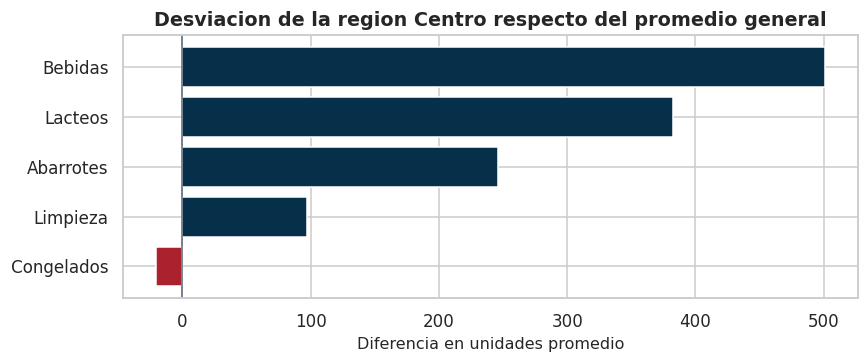

In [ ]:
media_general = ventas.groupby("categoria", observed=True)["unidades"].mean().mean()
desvio = (ventas.groupby(["region", "categoria"], observed=True)["unidades"].mean()
          .sub(media_general).loc["Centro"].sort_values())

fig, eje = plt.subplots(figsize=(8, 3.4))
colores = [DESTACADO if v < 0 else CONTRASTE for v in desvio.values]
eje.barh(desvio.index, desvio.values, color=colores)
eje.axvline(0, color="#5A6B7A", linewidth=1)

eje.set_title("Desviacion de la region Centro respecto del promedio general")
eje.set_xlabel("Diferencia en unidades promedio"); eje.set_ylabel("")
plt.tight_layout(); plt.show()

**El cero deja de ser el borde y pasa a ser el centro.** Eso convierte el gráfico en una
lectura de superávit y déficit, que es más directa que comparar dos barras separadas.

---
# III. Ver distribuciones

Responde preguntas sobre la forma: cómo se reparten los valores, dónde se concentran, si
hay valores extremos, si los grupos difieren.

### 3.1 Histograma

| | |
|---|---|
| **Qué es** | Barras que cuentan cuántas observaciones caen en cada intervalo |
| **Para qué sirve** | Conocer la forma de una variable continua |
| **Qué comunica** | Si es simétrica, si tiene cola, si tiene más de un pico |
| **Cuándo no usarlo** | Con menos de treinta observaciones: la figura muestra azar, no forma |

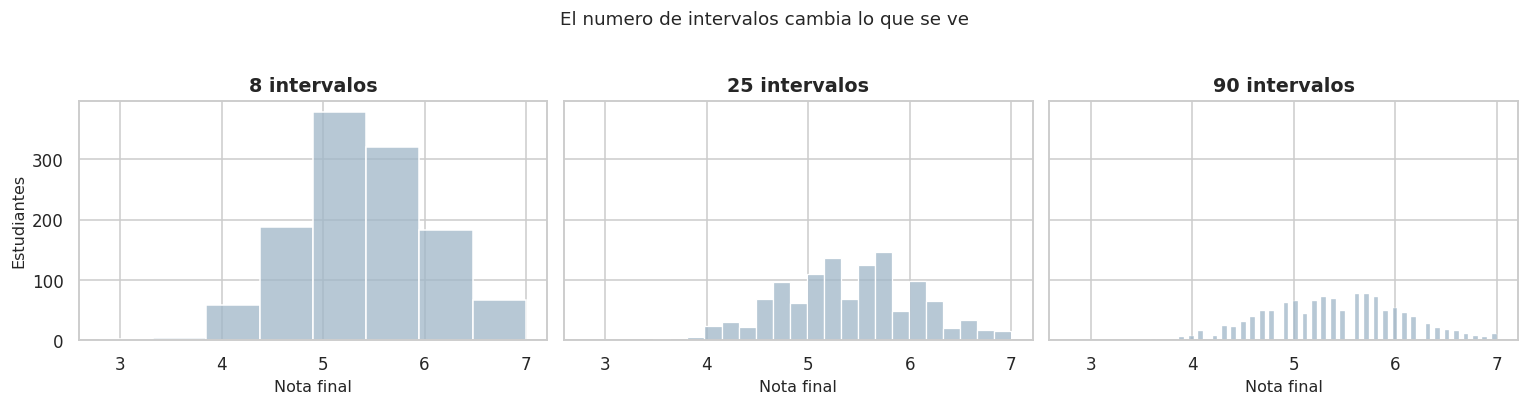

In [ ]:
fig, ejes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for eje, bins in zip(ejes, [8, 25, 90]):
    sns.histplot(data=alumnos, x="nota", bins=bins, color=NEUTRO, ax=eje)
    eje.set_title(f"{bins} intervalos")
    eje.set_xlabel("Nota final")
ejes[0].set_ylabel("Estudiantes")

fig.suptitle("El numero de intervalos cambia lo que se ve", y=1.04)
plt.tight_layout(); plt.show()

**Esta es la decisión que el histograma esconde.** Con pocos intervalos se pierde el
detalle; con demasiados aparece ruido que parece estructura. Prueben varios y declaren
cuál usaron, porque cambia la lectura.

### 3.2 Densidad

| | |
|---|---|
| **Qué es** | Una curva suavizada que estima la distribución |
| **Para qué sirve** | Comparar la forma de dos o tres grupos en una misma figura |
| **Qué comunica** | Dónde se concentra cada grupo y cuánto se superponen |
| **Cuándo no usarlo** | Con grupos pequeños: la curva inventa suavidad que los datos no tienen |

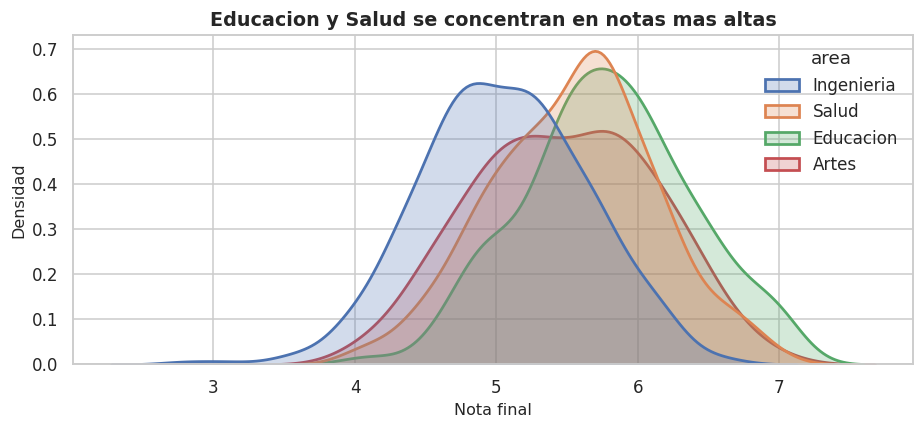

In [ ]:
fig, eje = plt.subplots(figsize=(8.5, 4))
sns.kdeplot(data=alumnos, x="nota", hue="area", fill=True, alpha=0.25,
            common_norm=False, linewidth=1.8, ax=eje)
eje.set_title("Educacion y Salud se concentran en notas mas altas")
eje.set_xlabel("Nota final"); eje.set_ylabel("Densidad")
plt.tight_layout(); plt.show()

**El argumento `common_norm=False` es decisivo.** Normaliza cada curva por separado, de
modo que grupos de tamaños distintos sean comparables en forma. Sin él, el grupo más
numeroso aplasta a los demás y la figura miente sobre las formas.

### 3.3 Distribución acumulada

| | |
|---|---|
| **Qué es** | Curva que muestra qué proporción de datos queda bajo cada valor |
| **Para qué sirve** | Responder preguntas del tipo qué porcentaje está por debajo de un umbral |
| **Qué comunica** | Percentiles y proporciones exactas, sin depender de intervalos |
| **Cuándo no usarlo** | Cuando interesa la forma de la distribución más que las proporciones |

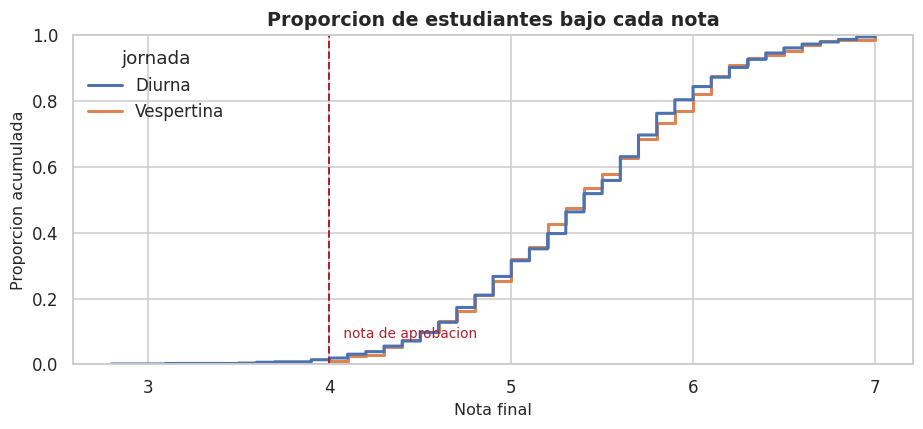

Porcentaje bajo 4,0 por jornada:
jornada
Diurna        1.4
Vespertina    0.2


In [ ]:
fig, eje = plt.subplots(figsize=(8.5, 4))
sns.ecdfplot(data=alumnos, x="nota", hue="jornada", linewidth=2, ax=eje)
eje.axvline(4.0, color=DESTACADO, linestyle="--", linewidth=1.3)
eje.text(4.05, 0.08, " nota de aprobacion", color=DESTACADO, fontsize=9)

eje.set_title("Proporcion de estudiantes bajo cada nota")
eje.set_xlabel("Nota final"); eje.set_ylabel("Proporcion acumulada")
plt.tight_layout(); plt.show()

print("Porcentaje bajo 4,0 por jornada:")
print((alumnos.assign(reprueba=alumnos["nota"] < 4)
       .groupby("jornada", observed=True)["reprueba"].mean().mul(100).round(1).to_string()))

**Es el gráfico más subestimado del catálogo.** A diferencia del histograma, no depende
de cómo se elijan los intervalos, y permite leer cualquier percentil directamente. Donde
la curva cruza la línea vertical se lee la proporción bajo ese umbral.

### 3.4 Gráfico de caja

| | |
|---|---|
| **Qué es** | Resumen de cinco números: mínimo, cuartiles, mediana y máximo |
| **Para qué sirve** | Comparar valor central y dispersión entre varios grupos |
| **Qué comunica** | Si un grupo está sistemáticamente por encima y cuánto varía cada uno |
| **Cuándo no usarlo** | Cuando el tamaño de los grupos es muy desigual: la caja no lo muestra |

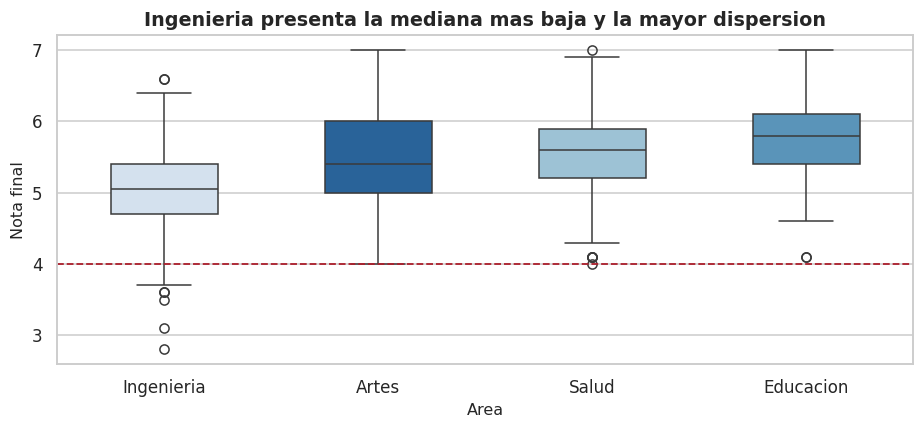

In [ ]:
fig, eje = plt.subplots(figsize=(8.5, 4))
orden = alumnos.groupby("area", observed=True)["nota"].median().sort_values().index
sns.boxplot(data=alumnos, x="area", y="nota", order=orden,
            hue="area", legend=False, palette="Blues", width=0.5, ax=eje)
eje.axhline(4.0, color=DESTACADO, linestyle="--", linewidth=1.2)

eje.set_title("Ingenieria presenta la mediana mas baja y la mayor dispersion")
eje.set_xlabel("Area"); eje.set_ylabel("Nota final")
plt.tight_layout(); plt.show()

**Ordenar las cajas por mediana convierte el gráfico en un ranking.** Y la línea de
referencia permite leer de inmediato qué parte de cada caja queda bajo el umbral.

### 3.5 Caja con puntos

| | |
|---|---|
| **Qué es** | Un gráfico de caja con las observaciones superpuestas |
| **Para qué sirve** | Mostrar el resumen y la evidencia que lo respalda a la vez |
| **Qué comunica** | Cuánta información hay detrás de cada caja |
| **Cuándo no usarlo** | Con decenas de miles de puntos: conviene muestrear o usar violín |

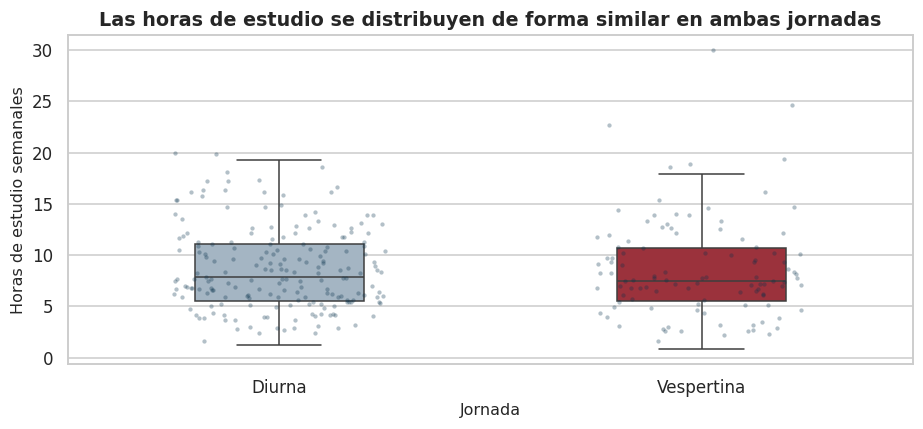

In [ ]:
fig, eje = plt.subplots(figsize=(8.5, 4))
sns.boxplot(data=alumnos, x="jornada", y="horas_estudio", hue="jornada", legend=False,
            palette=[NEUTRO, DESTACADO], width=0.4, fliersize=0, ax=eje)
sns.stripplot(data=alumnos.sample(300, random_state=SEMILLA),
              x="jornada", y="horas_estudio", size=2.8, color=CONTRASTE,
              alpha=0.3, jitter=0.25, ax=eje)

eje.set_title("Las horas de estudio se distribuyen de forma similar en ambas jornadas")
eje.set_xlabel("Jornada"); eje.set_ylabel("Horas de estudio semanales")
plt.tight_layout(); plt.show()

### 3.6 Violín

| | |
|---|---|
| **Qué es** | Una curva de densidad reflejada, con forma de violín |
| **Para qué sirve** | Comparar la forma completa de la distribución entre grupos |
| **Qué comunica** | Diferencias que la caja no revela, como dos picos |
| **Cuándo no usarlo** | Con menos de treinta observaciones por grupo |

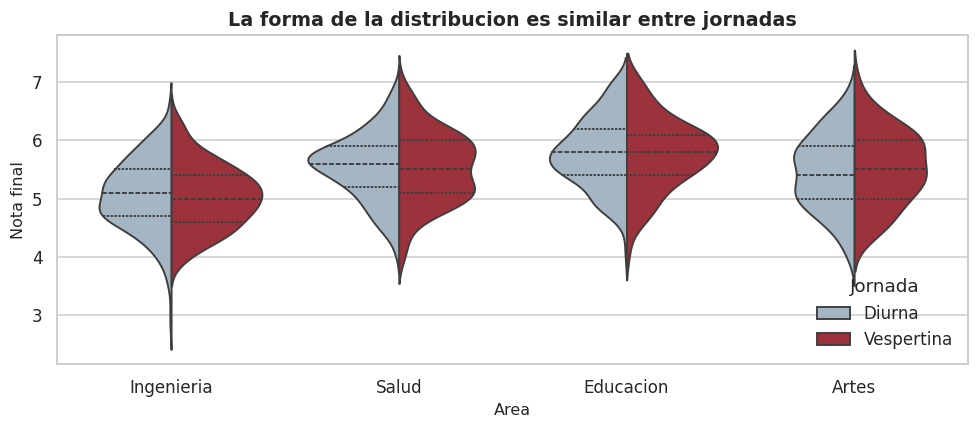

In [ ]:
fig, eje = plt.subplots(figsize=(9, 4))
sns.violinplot(data=alumnos, x="area", y="nota", hue="jornada", split=True,
               palette=[NEUTRO, DESTACADO], inner="quartile", ax=eje)
eje.legend(title="Jornada", loc="lower right")
eje.set_title("La forma de la distribucion es similar entre jornadas")
eje.set_xlabel("Area"); eje.set_ylabel("Nota final")
plt.tight_layout(); plt.show()

**El argumento `split=True` aprovecha la simetría del violín.** Pone un grupo en cada
mitad, lo que permite comparar dos series en el mismo espacio y con la misma línea base.

### 3.7 Enjambre

| | |
|---|---|
| **Qué es** | Puntos individuales desplazados lateralmente para que no se superpongan |
| **Para qué sirve** | Mostrar todas las observaciones cuando son pocas |
| **Qué comunica** | La distribución real, sin resumir ni suavizar |
| **Cuándo no usarlo** | Con más de unos cientos de puntos: se vuelve una mancha |

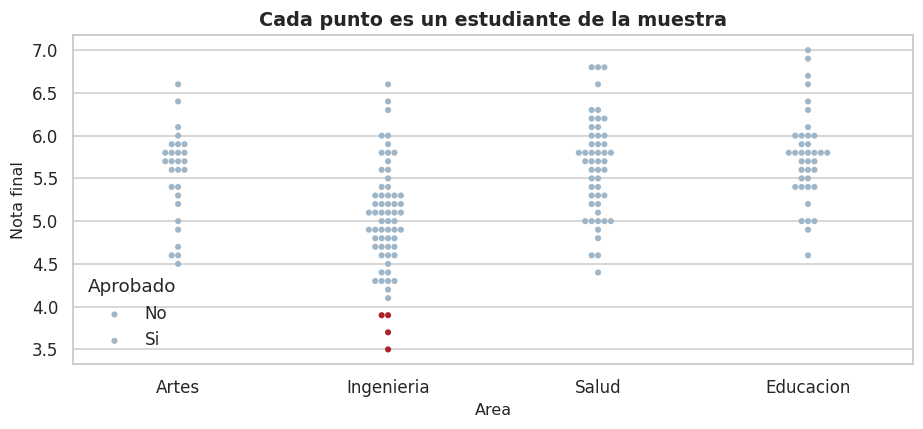

In [ ]:
muestra = alumnos.sample(180, random_state=SEMILLA)

fig, eje = plt.subplots(figsize=(8.5, 4))
sns.swarmplot(data=muestra, x="area", y="nota", hue="aprobado",
              palette=[DESTACADO, NEUTRO], size=4, ax=eje)
eje.legend(title="Aprobado", labels=["No", "Si"])
eje.set_title("Cada punto es un estudiante de la muestra")
eje.set_xlabel("Area"); eje.set_ylabel("Nota final")
plt.tight_layout(); plt.show()

---
# IV. Examinar relaciones

Responde si dos variables se mueven juntas, en qué dirección y con qué fuerza.

### 4.1 Dispersión

| | |
|---|---|
| **Qué es** | Cada observación como un punto en dos ejes |
| **Para qué sirve** | Examinar la relación entre dos variables continuas |
| **Qué comunica** | Dirección, fuerza, agrupamientos y valores atípicos |
| **Cuándo no usarlo** | Con decenas de miles de puntos superpuestos: usen hexágonos |

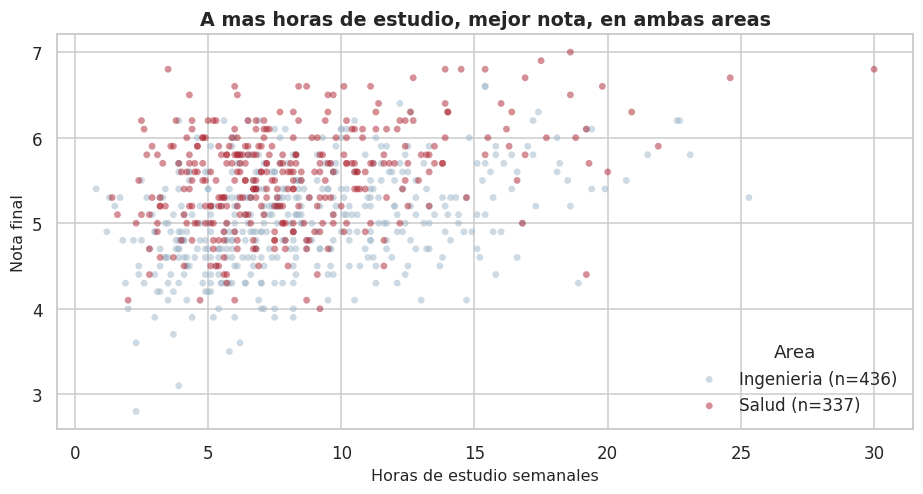

In [ ]:
fig, eje = plt.subplots(figsize=(8.5, 4.6))
for area, color in zip(["Ingenieria", "Salud"], [NEUTRO, DESTACADO]):
    sub = alumnos[alumnos["area"] == area]
    eje.scatter(sub["horas_estudio"], sub["nota"], s=20, alpha=0.5,
                color=color, edgecolors="none", label=f"{area} (n={len(sub)})")
eje.legend(title="Area")
eje.set_title("A mas horas de estudio, mejor nota, en ambas areas")
eje.set_xlabel("Horas de estudio semanales"); eje.set_ylabel("Nota final")
plt.tight_layout(); plt.show()

### 4.2 Dispersión con tendencia

| | |
|---|---|
| **Qué es** | Una dispersión con su ajuste y su banda de confianza |
| **Para qué sirve** | Cuantificar la dirección y la magnitud de la relación |
| **Qué comunica** | Cuánto cambia una variable por unidad de la otra |
| **Cuándo no usarlo** | Cuando la relación es claramente curva: el ajuste lineal la oculta |

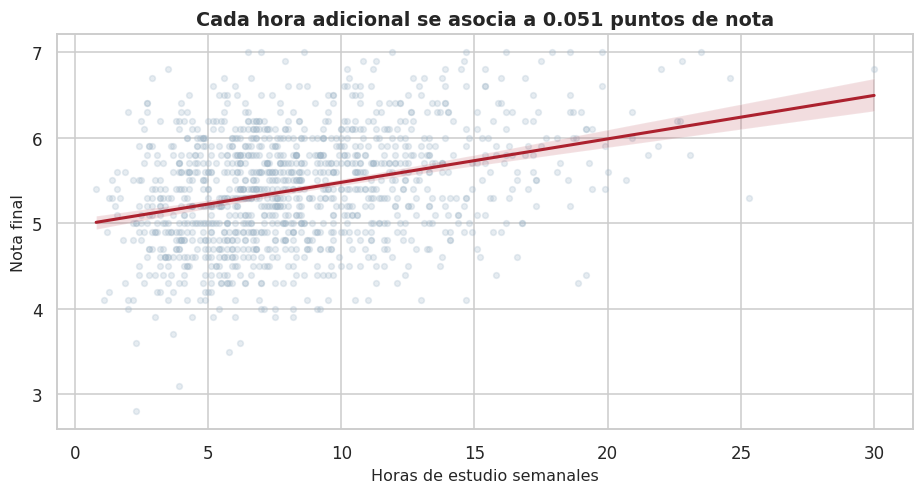

Pendiente: 0.0508 | Correlacion: 0.326
Asociacion observada. No permite afirmar causalidad.


In [ ]:
fig, eje = plt.subplots(figsize=(8.5, 4.6))
sns.regplot(data=alumnos, x="horas_estudio", y="nota",
            scatter_kws={"s": 14, "alpha": 0.25, "color": NEUTRO},
            line_kws={"color": DESTACADO, "linewidth": 2}, ax=eje)

pendiente, intercepto = np.polyfit(alumnos["horas_estudio"], alumnos["nota"], 1)
correlacion = alumnos[["horas_estudio", "nota"]].corr().iloc[0, 1]

eje.set_title(f"Cada hora adicional se asocia a {pendiente:.3f} puntos de nota")
eje.set_xlabel("Horas de estudio semanales"); eje.set_ylabel("Nota final")
plt.tight_layout(); plt.show()

print(f"Pendiente: {pendiente:.4f} | Correlacion: {correlacion:.3f}")
print("Asociacion observada. No permite afirmar causalidad.")

**Reportar la pendiente convierte una impresión en una cifra.** Y la advertencia final no
es un formalismo: una relación observada entre horas de estudio y nota podría explicarse
por una tercera variable, como la motivación o el tiempo disponible.

### 4.3 Burbujas

| | |
|---|---|
| **Qué es** | Una dispersión donde el tamaño del punto codifica una tercera variable |
| **Para qué sirve** | Mostrar tres variables numéricas a la vez |
| **Qué comunica** | La relación entre dos variables y la magnitud de una tercera |
| **Cuándo no usarlo** | Cuando la tercera variable es lo importante: el área se estima mal |

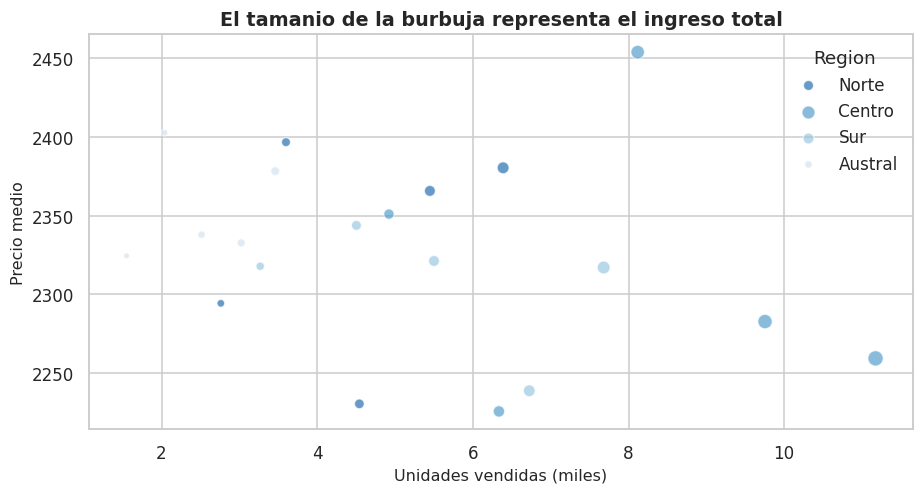

In [ ]:
resumen = (ventas.groupby(["region", "categoria"], observed=True)
           .agg(unidades=("unidades", "sum"), ingreso=("ingreso", "sum"))
           .reset_index())
resumen["precio_medio"] = resumen["ingreso"] / resumen["unidades"]

fig, eje = plt.subplots(figsize=(8.5, 4.6))
for region, color in zip(regiones, sns.color_palette("Blues_r", 4)):
    sub = resumen[resumen["region"] == region]
    eje.scatter(sub["unidades"] / 1000, sub["precio_medio"],
                s=sub["ingreso"] / 1e6 * 4, alpha=0.65, color=color,
                edgecolors="white", linewidth=0.8, label=region)
eje.legend(title="Region", loc="upper right")
eje.set_title("El tamanio de la burbuja representa el ingreso total")
eje.set_xlabel("Unidades vendidas (miles)"); eje.set_ylabel("Precio medio")
plt.tight_layout(); plt.show()

**Advertencia sobre el tamaño.** El área ocupa el quinto lugar en la jerarquía
perceptual, así que sirve para señalar magnitudes gruesas y no para compararlas con
precisión. Si la tercera variable es central, conviene otro gráfico.

### 4.4 Hexágonos

| | |
|---|---|
| **Qué es** | Divide el plano en hexágonos y cuenta cuántos puntos caen en cada uno |
| **Para qué sirve** | Ver la densidad cuando hay tantos puntos que la dispersión se satura |
| **Qué comunica** | Dónde se concentran las observaciones |
| **Cuándo no usarlo** | Con pocos datos: cada hexágono contiene uno o dos puntos |

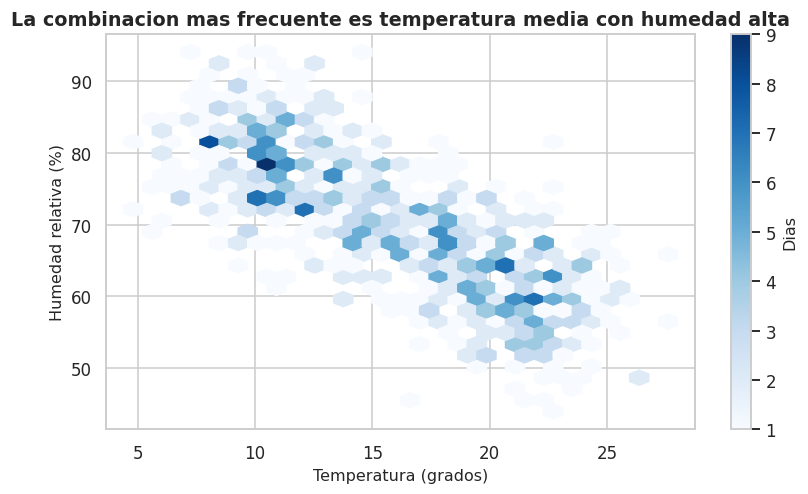

In [ ]:
fig, eje = plt.subplots(figsize=(7.5, 4.6))
hb = eje.hexbin(clima["temperatura"], clima["humedad"], gridsize=28,
                cmap="Blues", mincnt=1)
fig.colorbar(hb, ax=eje, label="Dias")

eje.set_title("La combinacion mas frecuente es temperatura media con humedad alta")
eje.set_xlabel("Temperatura (grados)"); eje.set_ylabel("Humedad relativa (%)")
plt.tight_layout(); plt.show()

### 4.5 Gráfico conjunto

| | |
|---|---|
| **Qué es** | Una dispersión con las distribuciones de cada variable en los márgenes |
| **Para qué sirve** | Ver la relación y las dos distribuciones en una sola figura |
| **Qué comunica** | Si la relación se explica por la forma de alguna de las variables |
| **Cuándo no usarlo** | Cuando se necesita espacio: ocupa más que una dispersión simple |

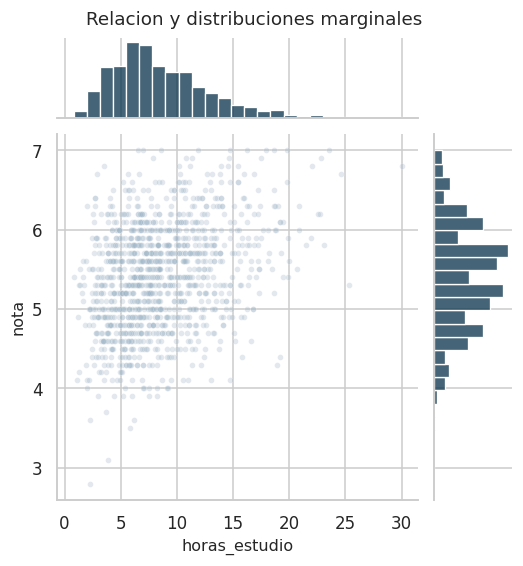

In [ ]:
grafico = sns.jointplot(data=alumnos, x="horas_estudio", y="nota",
                        kind="scatter", height=5, ratio=4,
                        joint_kws={"s": 14, "alpha": 0.3, "color": NEUTRO},
                        marginal_kws={"color": CONTRASTE, "bins": 25})
grafico.figure.suptitle("Relacion y distribuciones marginales", y=1.02)
plt.show()

---
# V. Seguir una evolución

Responde cómo cambia una medida a lo largo de una secuencia ordenada: tiempo, tramos,
niveles.

### 5.1 Líneas

| | |
|---|---|
| **Qué es** | Puntos unidos en el orden de la secuencia |
| **Para qué sirve** | Mostrar la trayectoria de una medida en el tiempo |
| **Qué comunica** | Tendencia, quiebres, estacionalidad y velocidad del cambio |
| **Cuándo no usarlo** | Con categorías sin orden: la línea sugiere continuidad inexistente |

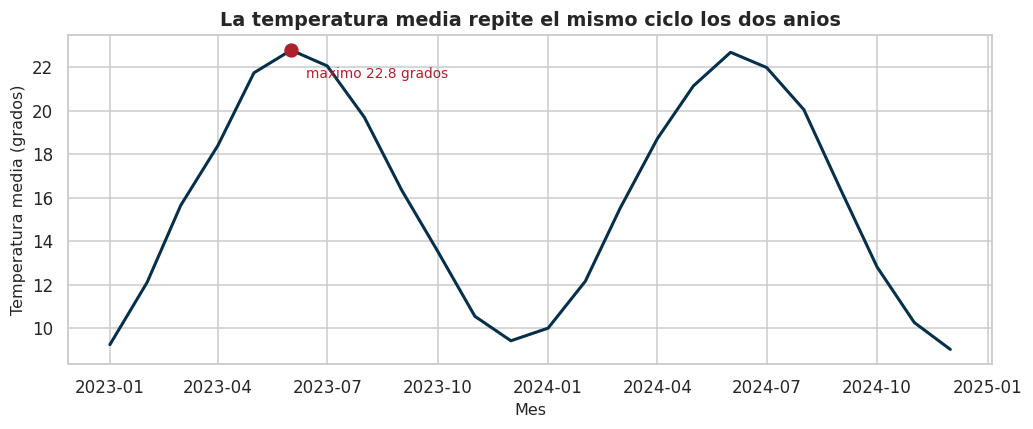

In [ ]:
mensual = clima.set_index("fecha")["temperatura"].resample("MS").mean()

fig, eje = plt.subplots(figsize=(9.5, 4))
eje.plot(mensual.index, mensual.values, linewidth=2, color=CONTRASTE)
eje.scatter(mensual.idxmax(), mensual.max(), s=70, color=DESTACADO, zorder=5)
eje.annotate(f"maximo {mensual.max():.1f} grados",
             xy=(mensual.idxmax(), mensual.max()),
             xytext=(10, -18), textcoords="offset points",
             color=DESTACADO, fontsize=9)

eje.set_title("La temperatura media repite el mismo ciclo los dos anios")
eje.set_xlabel("Mes"); eje.set_ylabel("Temperatura media (grados)")
plt.tight_layout(); plt.show()

### 5.2 Varias series

| | |
|---|---|
| **Qué es** | Una línea por grupo sobre los mismos ejes |
| **Para qué sirve** | Comparar trayectorias de distintos grupos |
| **Qué comunica** | Si las series se mueven juntas, se cruzan o divergen |
| **Cuándo no usarlo** | Con más de cinco o seis líneas: usen paneles múltiples |

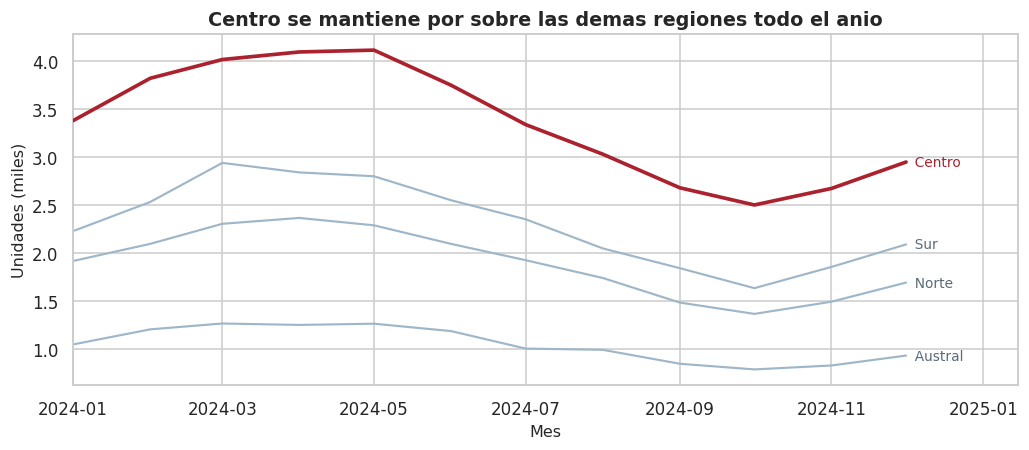

In [ ]:
serie = (ventas.groupby(["mes", "region"], observed=True)["unidades"]
         .sum().div(1000).unstack())

fig, eje = plt.subplots(figsize=(9.5, 4.2))
for region in serie.columns:
    destaca = region == "Centro"
    eje.plot(serie.index, serie[region], linewidth=2.4 if destaca else 1.4,
             color=DESTACADO if destaca else NEUTRO,
             label=region, zorder=3 if destaca else 2)
    # Rotular al final de la línea evita la leyenda
    eje.text(serie.index[-1], serie[region].iloc[-1], f"  {region}",
             fontsize=9, va="center",
             color=DESTACADO if destaca else "#5A6B7A")

eje.set_xlim(serie.index.min(), serie.index.max() + pd.Timedelta(days=45))
eje.set_title("Centro se mantiene por sobre las demas regiones todo el anio")
eje.set_xlabel("Mes"); eje.set_ylabel("Unidades (miles)")
plt.tight_layout(); plt.show()

**Dos técnicas que conviene adoptar.** Destacar una serie y dejar el resto en gris
convierte un gráfico de cuatro líneas en un gráfico sobre una línea. Y rotular al final
de cada línea elimina la leyenda, que obliga al ojo a ir y volver.

### 5.3 Área

| | |
|---|---|
| **Qué es** | Una línea con la superficie bajo ella rellena |
| **Para qué sirve** | Enfatizar la magnitud acumulada de una serie única |
| **Qué comunica** | El volumen total además de la trayectoria |
| **Cuándo no usarlo** | Con varias series superpuestas: se ocultan entre sí |

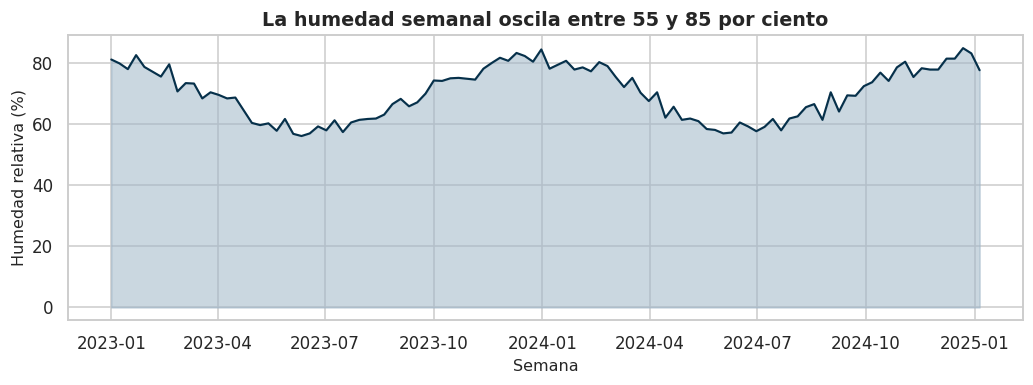

In [ ]:
diario = clima.set_index("fecha")["humedad"].resample("W").mean()

fig, eje = plt.subplots(figsize=(9.5, 3.6))
eje.fill_between(diario.index, diario.values, color=NEUTRO, alpha=0.55)
eje.plot(diario.index, diario.values, color=CONTRASTE, linewidth=1.4)

eje.set_title("La humedad semanal oscila entre 55 y 85 por ciento")
eje.set_xlabel("Semana"); eje.set_ylabel("Humedad relativa (%)")
plt.tight_layout(); plt.show()

### 5.4 Área apilada

| | |
|---|---|
| **Qué es** | Varias series apiladas, mostrando el total y su composición |
| **Para qué sirve** | Ver cómo evoluciona el total y qué aporta cada componente |
| **Qué comunica** | Crecimiento del total y cambios en la mezcla |
| **Cuándo no usarlo** | Cuando importa comparar componentes entre sí: solo el de abajo tiene base fija |

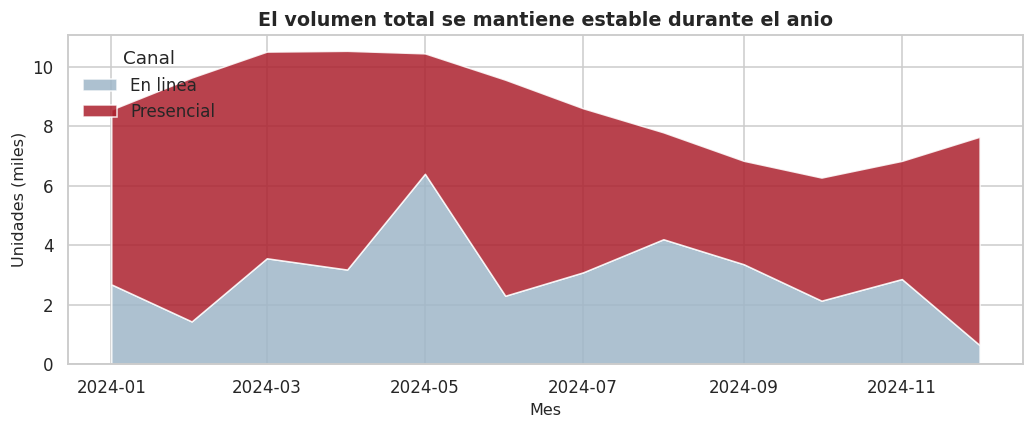

In [ ]:
composicion = (ventas.groupby(["mes", "canal"], observed=True)["unidades"]
               .sum().div(1000).unstack())

fig, eje = plt.subplots(figsize=(9.5, 4))
eje.stackplot(composicion.index, composicion.T.values,
              labels=composicion.columns,
              colors=[NEUTRO, DESTACADO], alpha=0.85)
eje.legend(loc="upper left", title="Canal")
eje.set_title("El volumen total se mantiene estable durante el anio")
eje.set_xlabel("Mes"); eje.set_ylabel("Unidades (miles)")
plt.tight_layout(); plt.show()

### 5.5 Gráfico de pendiente

| | |
|---|---|
| **Qué es** | Dos momentos unidos por una línea, uno por categoría |
| **Para qué sirve** | Comparar el cambio entre dos períodos en varias categorías |
| **Qué comunica** | Quién subió, quién bajó y quién cambió de posición |
| **Cuándo no usarlo** | Con más de dos momentos: corresponde un gráfico de líneas |

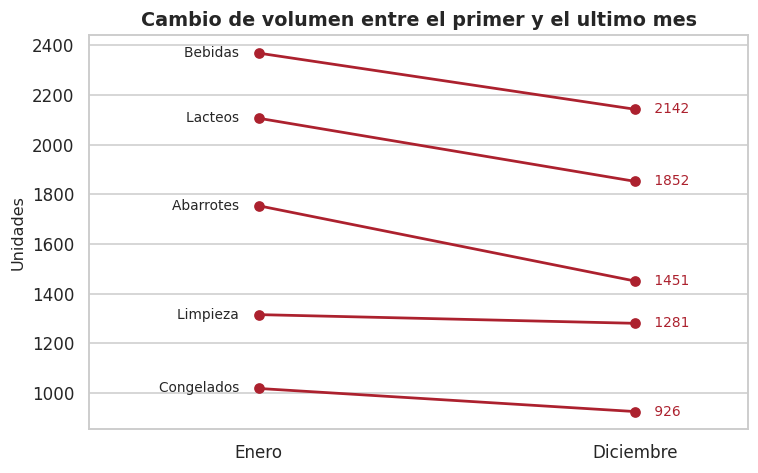

In [ ]:
primero = ventas[ventas["mes"] == meses[0]].groupby("categoria", observed=True)["unidades"].sum()
ultimo = ventas[ventas["mes"] == meses[-1]].groupby("categoria", observed=True)["unidades"].sum()

fig, eje = plt.subplots(figsize=(7, 4.4))
for cat in primero.index:
    sube = ultimo[cat] >= primero[cat]
    color = CONTRASTE if sube else DESTACADO
    eje.plot([0, 1], [primero[cat], ultimo[cat]], marker="o", color=color, linewidth=1.8)
    eje.text(-0.04, primero[cat], f"{cat} ", ha="right", va="center", fontsize=9)
    eje.text(1.04, ultimo[cat], f" {ultimo[cat]:.0f}", ha="left", va="center",
             fontsize=9, color=color)

eje.set_xticks([0, 1], ["Enero", "Diciembre"])
eje.set_xlim(-0.45, 1.3)
eje.set_title("Cambio de volumen entre el primer y el ultimo mes")
eje.set_ylabel("Unidades")
eje.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

**Es el gráfico más claro para un antes y un después.** La pendiente codifica el cambio
mediante posición, que es el canal más preciso, y el cruce de líneas muestra de inmediato
si hubo cambios de posición relativa.

---
# VI. Mostrar composición

Responde de qué partes se compone un total y cómo cambia esa mezcla entre grupos.

### 6.1 Barras apiladas al cien por ciento

| | |
|---|---|
| **Qué es** | Barras normalizadas donde cada segmento es una proporción |
| **Para qué sirve** | Comparar la composición entre grupos de tamaños distintos |
| **Qué comunica** | Cómo cambia la proporción de cada componente |
| **Cuándo no usarlo** | Con más de cuatro o cinco componentes: los intermedios no se comparan |

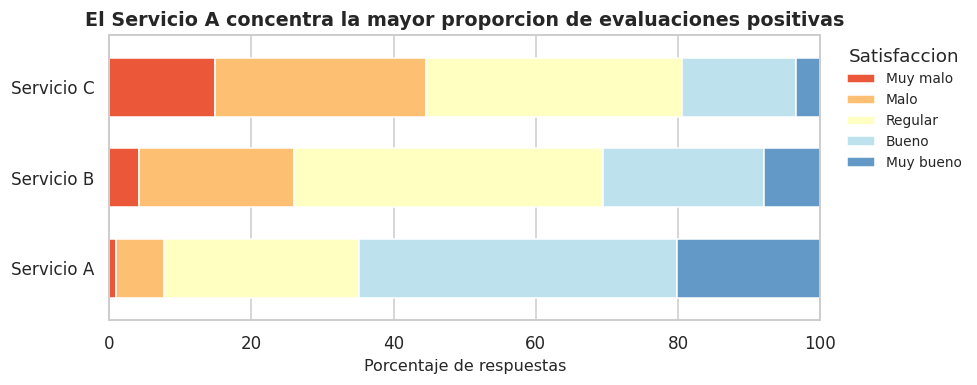

In [ ]:
composicion = (pd.crosstab(encuesta["grupo"], encuesta["satisfaccion"], normalize="index")
               .mul(100).round(1))

fig, eje = plt.subplots(figsize=(9, 3.6))
composicion.plot(kind="barh", stacked=True, ax=eje,
                 color=sns.color_palette("RdYlBu", composicion.shape[1]), width=0.65)
eje.legend(title="Satisfaccion", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
eje.set_xlim(0, 100)
eje.set_title("El Servicio A concentra la mayor proporcion de evaluaciones positivas")
eje.set_xlabel("Porcentaje de respuestas"); eje.set_ylabel("")
plt.tight_layout(); plt.show()

**Para variables ordinales, la paleta debe respetar el orden.** Acá una paleta divergente
lleva del rojo al azul pasando por el amarillo, de modo que el color transmite la misma
información que la posición del segmento.

### 6.2 Barras divergentes de escala

| | |
|---|---|
| **Qué es** | Segmentos negativos y positivos a partir de un centro neutro |
| **Para qué sirve** | Presentar escalas de acuerdo o satisfacción |
| **Qué comunica** | El balance entre respuestas favorables y desfavorables |
| **Cuándo no usarlo** | Cuando no hay una categoría central que sirva de eje |

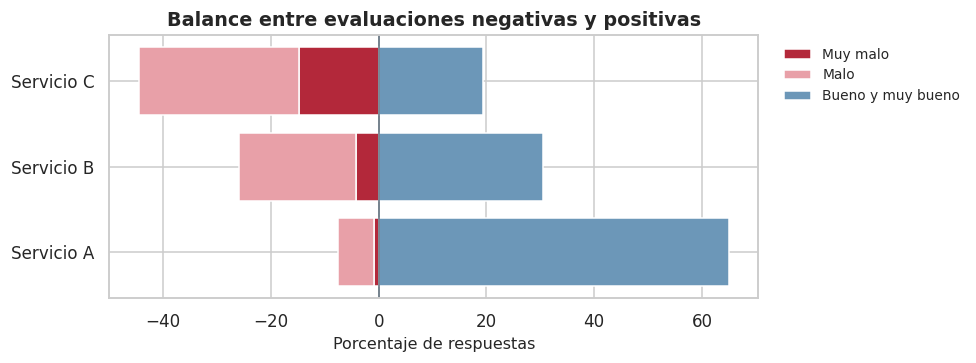

In [ ]:
tabla = pd.crosstab(encuesta["grupo"], encuesta["satisfaccion"], normalize="index").mul(100)

negativos = -(tabla[["Muy malo", "Malo"]].sum(axis=1) + tabla["Regular"] / 2)
neutro = tabla["Regular"]
positivos = tabla[["Bueno", "Muy bueno"]].sum(axis=1)

fig, eje = plt.subplots(figsize=(9, 3.4))
eje.barh(tabla.index, tabla["Muy malo"] * -1, color="#B3283A", label="Muy malo")
eje.barh(tabla.index, tabla["Malo"] * -1, left=tabla["Muy malo"] * -1,
         color="#E8A0A8", label="Malo")
eje.barh(tabla.index, positivos, color="#6C97B8", label="Bueno y muy bueno")
eje.axvline(0, color="#5A6B7A", linewidth=1)

eje.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
eje.set_title("Balance entre evaluaciones negativas y positivas")
eje.set_xlabel("Porcentaje de respuestas"); eje.set_ylabel("")
plt.tight_layout(); plt.show()

### 6.3 Circular y anillo

| | |
|---|---|
| **Qué es** | Sectores cuyo ángulo representa la proporción |
| **Para qué sirve** | Mostrar una partición simple, de dos o tres categorías |
| **Qué comunica** | Que las partes suman un todo |
| **Cuándo no usarlo** | Con más de tres categorías: comparar ángulos es impreciso |

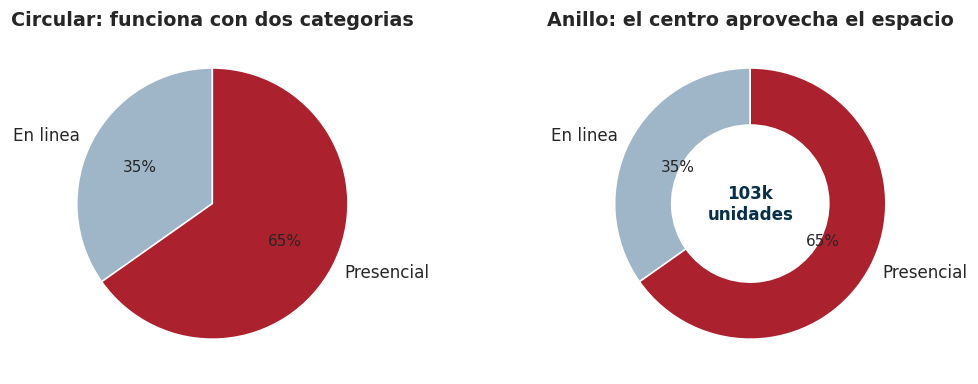

In [ ]:
canal = ventas.groupby("canal", observed=True)["unidades"].sum()

fig, ejes = plt.subplots(1, 2, figsize=(10, 3.6))
ejes[0].pie(canal.values, labels=canal.index, autopct="%1.0f%%",
            colors=[NEUTRO, DESTACADO], startangle=90)
ejes[0].set_title("Circular: funciona con dos categorias")

# Anillo: el centro sirve para poner la cifra principal
ejes[1].pie(canal.values, labels=canal.index, autopct="%1.0f%%",
            colors=[NEUTRO, DESTACADO], startangle=90,
            wedgeprops={"width": 0.42})
ejes[1].text(0, 0, f"{canal.sum()/1000:.0f}k\nunidades", ha="center", va="center",
             fontsize=11, fontweight="bold", color=CONTRASTE)
ejes[1].set_title("Anillo: el centro aprovecha el espacio")

plt.tight_layout(); plt.show()

**Con dos categorías el circular funciona**, porque comparar un sector con su
complemento es una tarea fácil. El problema empieza en la cuarta categoría. El anillo,
además, deja libre el centro para la cifra que resume la figura.

---
# VII. Panoramas y matrices

Responde qué estructura tiene el conjunto: qué variables se relacionan, qué combinaciones
son frecuentes.

### 7.1 Mapa de calor de correlaciones

| | |
|---|---|
| **Qué es** | Matriz donde el color codifica la correlación entre cada par |
| **Para qué sirve** | Explorar qué variables numéricas se mueven juntas |
| **Qué comunica** | Un panorama de las asociaciones lineales |
| **Cuándo no usarlo** | Como resultado final: solo mide relación lineal y no explica nada |

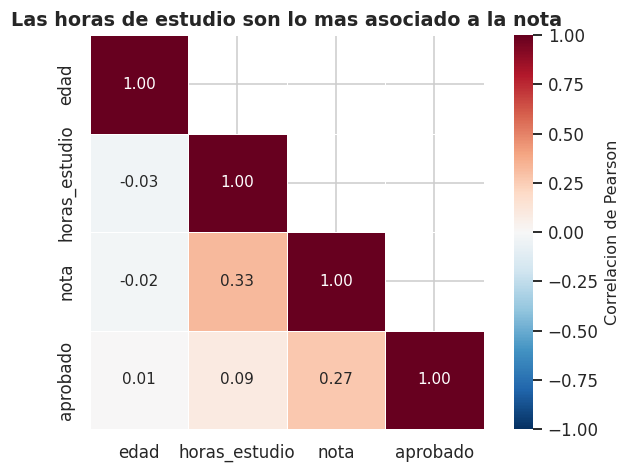

In [ ]:
numericas = alumnos[["edad", "horas_estudio", "nota", "aprobado"]]
correlaciones = numericas.corr()

# La máscara oculta la mitad superior, que es redundante
mascara = np.triu(np.ones_like(correlaciones, dtype=bool), k=1)

fig, eje = plt.subplots(figsize=(6, 4.4))
sns.heatmap(correlaciones, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, vmin=-1, vmax=1, square=True, linewidths=0.6,
            cbar_kws={"label": "Correlacion de Pearson"}, ax=eje)
eje.set_title("Las horas de estudio son lo mas asociado a la nota")
plt.tight_layout(); plt.show()

**Dos decisiones de diseño.** La máscara elimina la mitad redundante de la matriz, que es
espejo de la otra. Y la escala fija entre menos uno y uno, centrada en cero, evita que
correlaciones bajas se vean intensas.

### 7.2 Mapa de calor de tabla cruzada

| | |
|---|---|
| **Qué es** | Matriz donde el color codifica frecuencia o proporción |
| **Para qué sirve** | Examinar la relación entre dos variables categóricas |
| **Qué comunica** | Qué combinaciones son más frecuentes de lo esperado |
| **Cuándo no usarlo** | Con muchas categorías: la matriz se vuelve ilegible |

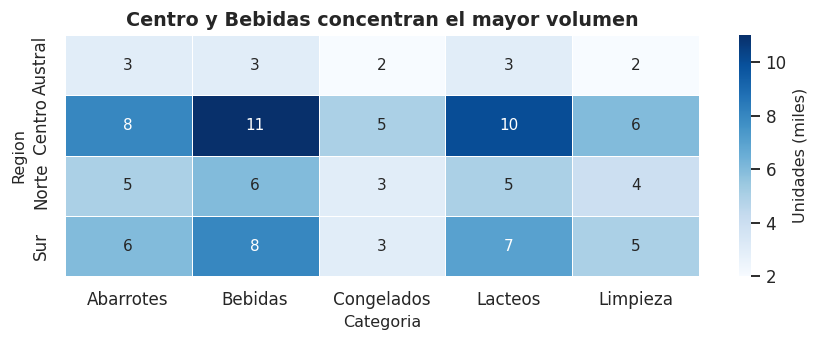

In [ ]:
tabla = pd.crosstab(ventas["region"], ventas["categoria"],
                    values=ventas["unidades"], aggfunc="sum").div(1000).round(0)

fig, eje = plt.subplots(figsize=(8, 3.2))
sns.heatmap(tabla, annot=True, fmt=".0f", cmap="Blues", linewidths=0.6,
            cbar_kws={"label": "Unidades (miles)"}, ax=eje)
eje.set_title("Centro y Bebidas concentran el mayor volumen")
eje.set_xlabel("Categoria"); eje.set_ylabel("Region")
plt.tight_layout(); plt.show()

### 7.3 Matriz de dispersión

| | |
|---|---|
| **Qué es** | Todas las combinaciones de pares entre varias variables |
| **Para qué sirve** | Explorar la estructura del conjunto al comienzo del análisis |
| **Qué comunica** | Relaciones que no se anticipaban |
| **Cuándo no usarlo** | En el informe: muestra mucho y no afirma nada, va en anexos |

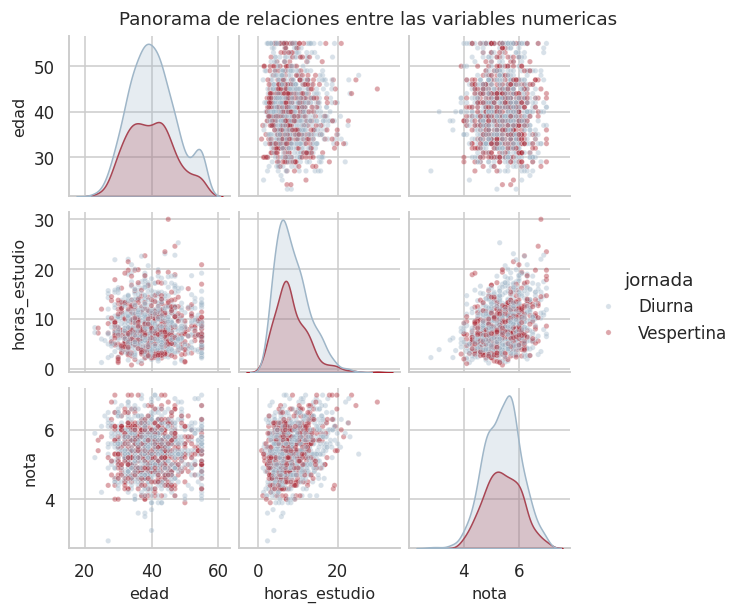

In [ ]:
grafico = sns.pairplot(alumnos[["edad", "horas_estudio", "nota", "jornada"]],
                       hue="jornada", palette=[NEUTRO, DESTACADO],
                       plot_kws={"s": 12, "alpha": 0.4}, height=1.8)
grafico.figure.suptitle("Panorama de relaciones entre las variables numericas", y=1.02)
plt.show()

---
# VIII. Paneles y anotación

Dos recursos que sirven para cualquier familia de gráficos.

### 8.1 Paneles múltiples

| | |
|---|---|
| **Qué es** | El mismo gráfico repetido para cada nivel de una variable |
| **Para qué sirve** | Comparar subgrupos sin saturar una sola figura, y estratificar |
| **Qué comunica** | Si un patrón se mantiene o cambia entre subgrupos |
| **Cuándo no usarlo** | Con más de nueve paneles: se vuelven ilegibles |

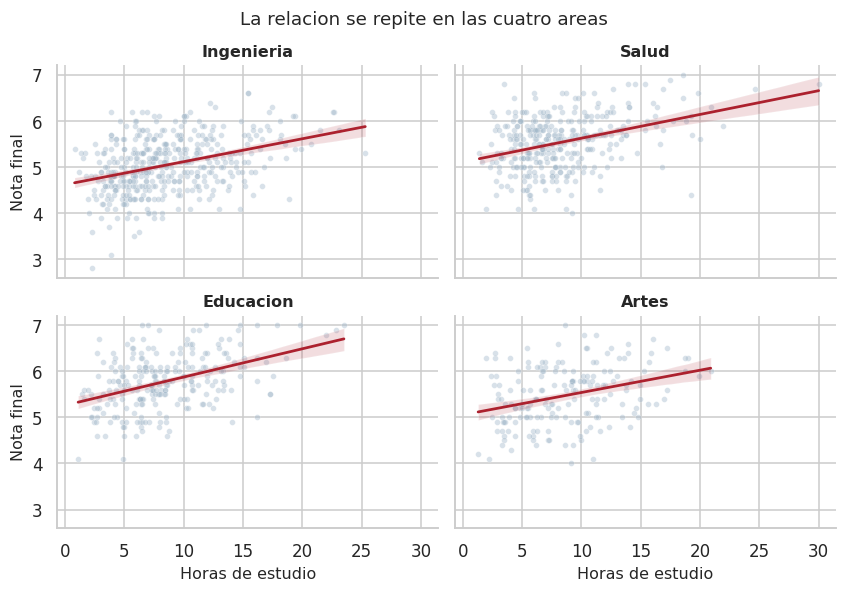

In [ ]:
grilla = sns.FacetGrid(alumnos, col="area", col_wrap=2, height=2.6,
                       aspect=1.5, sharey=True)
grilla.map_dataframe(sns.scatterplot, x="horas_estudio", y="nota",
                     s=14, alpha=0.4, color=NEUTRO)
grilla.map_dataframe(sns.regplot, x="horas_estudio", y="nota", scatter=False,
                     line_kws={"color": DESTACADO, "linewidth": 1.8})
grilla.set_axis_labels("Horas de estudio", "Nota final")
grilla.set_titles("{col_name}")
grilla.figure.suptitle("La relacion se repite en las cuatro areas", y=1.03)
plt.show()

**Los paneles son la forma más simple de estratificar.** Si sospechan que una diferencia
entre grupos se debe a una tercera variable, dividan por esa variable y comprueben si la
diferencia persiste. Es el procedimiento que permite detectar confusión.

**Mantengan los ejes compartidos.** Si cada panel usa su propia escala, la comparación
entre paneles deja de ser válida, que es justamente para lo que sirven.

### 8.2 Composición manual de paneles

| | |
|---|---|
| **Qué es** | Varios gráficos distintos organizados en una figura |
| **Para qué sirve** | Contar una secuencia completa en una sola imagen |
| **Qué comunica** | La relación entre distintos aspectos del mismo fenómeno |
| **Cuándo no usarlo** | Cuando cada gráfico merece su propia interpretación extensa |

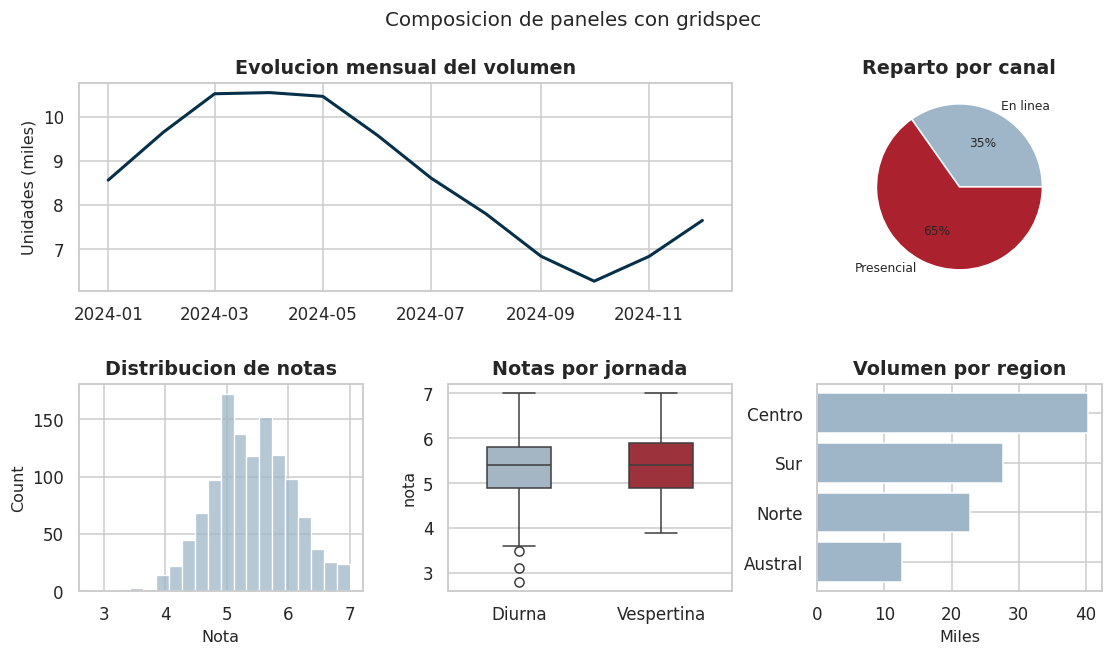

In [ ]:
fig = plt.figure(figsize=(12, 6))
malla = fig.add_gridspec(2, 3, hspace=0.45, wspace=0.3)

# Panel principal, ocupa dos columnas
eje1 = fig.add_subplot(malla[0, :2])
serie = ventas.groupby("mes", observed=True)["unidades"].sum().div(1000)
eje1.plot(serie.index, serie.values, linewidth=2, color=CONTRASTE)
eje1.set_title("Evolucion mensual del volumen")
eje1.set_ylabel("Unidades (miles)")

eje2 = fig.add_subplot(malla[0, 2])
por_canal = ventas.groupby("canal", observed=True)["unidades"].sum()
eje2.pie(por_canal.values, labels=por_canal.index, autopct="%1.0f%%",
         colors=[NEUTRO, DESTACADO], textprops={"fontsize": 8})
eje2.set_title("Reparto por canal")

eje3 = fig.add_subplot(malla[1, 0])
sns.histplot(data=alumnos, x="nota", bins=20, color=NEUTRO, ax=eje3)
eje3.set_title("Distribucion de notas"); eje3.set_xlabel("Nota")

eje4 = fig.add_subplot(malla[1, 1])
sns.boxplot(data=alumnos, x="jornada", y="nota", hue="jornada", legend=False,
            palette=[NEUTRO, DESTACADO], width=0.45, ax=eje4)
eje4.set_title("Notas por jornada"); eje4.set_xlabel("")

eje5 = fig.add_subplot(malla[1, 2])
por_region = ventas.groupby("region", observed=True)["unidades"].sum().div(1000).sort_values()
eje5.barh(por_region.index, por_region.values, color=NEUTRO)
eje5.set_title("Volumen por region"); eje5.set_xlabel("Miles")

fig.suptitle("Composicion de paneles con gridspec", fontsize=13, y=0.99)
plt.show()

### 8.3 Anotación y énfasis

| | |
|---|---|
| **Qué es** | Texto, flechas y formas que señalan un punto de la figura |
| **Para qué sirve** | Dirigir la mirada al lugar donde está el hallazgo |
| **Qué comunica** | Lo que el autor quiere que el lector note primero |
| **Cuándo no usarlo** | Cuando se abusa: tres anotaciones en una figura anulan el efecto |

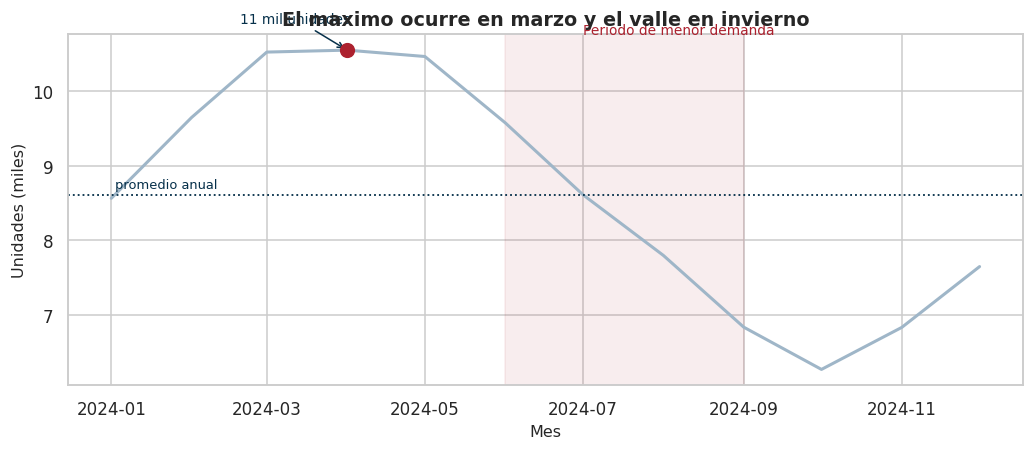

In [ ]:
serie = ventas.groupby("mes", observed=True)["unidades"].sum().div(1000)
maximo, minimo = serie.idxmax(), serie.idxmin()

fig, eje = plt.subplots(figsize=(9.5, 4.2))
eje.plot(serie.index, serie.values, linewidth=2, color=NEUTRO)

# Franja que resalta un período
eje.axvspan(meses[5], meses[8], color=DESTACADO, alpha=0.08)
eje.text(meses[6], serie.max() * 1.02, "Periodo de menor demanda",
         fontsize=9, color=DESTACADO)

# Punto y flecha sobre el máximo
eje.scatter(maximo, serie.max(), s=80, color=DESTACADO, zorder=5)
eje.annotate(f"{serie.max():.0f} mil unidades",
             xy=(maximo, serie.max()), xytext=(-70, 18),
             textcoords="offset points", color=CONTRASTE, fontsize=9,
             arrowprops=dict(arrowstyle="->", color=CONTRASTE))

# Línea de referencia
eje.axhline(serie.mean(), color=CONTRASTE, linestyle=":", linewidth=1.2)
eje.text(serie.index[0], serie.mean() * 1.01, " promedio anual",
         fontsize=8.5, color=CONTRASTE)

eje.set_title("El maximo ocurre en marzo y el valle en invierno")
eje.set_xlabel("Mes"); eje.set_ylabel("Unidades (miles)")
plt.tight_layout(); plt.show()

**Cuatro recursos de énfasis en una figura.** La franja marca un período, el punto y la
flecha señalan el extremo, la línea de referencia da el contexto, y el gris del resto deja
que todo eso destaque. Úsenlos con moderación: si todo está destacado, nada lo está.

---
# IX. Cómo elegir, en resumen

| Si la pregunta es | Gráfico principal | Alternativas |
|---|---|---|
| ¿Cuánto tiene cada grupo? | Barras ordenadas | Paletas si son muchas categorías |
| ¿Cómo se desvía cada grupo de una referencia? | Barras divergentes | |
| ¿Cómo se distribuyen los valores? | Histograma | Densidad para comparar grupos |
| ¿Qué proporción está bajo un umbral? | Distribución acumulada | |
| ¿Cómo se comparan las distribuciones? | Caja con puntos | Violín si la forma importa |
| ¿Se relacionan estas dos variables? | Dispersión | Con tendencia para la pendiente |
| ¿Y si hay demasiados puntos? | Hexágonos | |
| ¿Hay una tercera variable numérica? | Burbujas | Color en vez de tamaño |
| ¿Cómo cambia en el tiempo? | Líneas | Área para una sola serie |
| ¿Cómo cambió entre dos momentos? | Gráfico de pendiente | |
| ¿De qué se compone el total? | Barras apiladas al cien | Circular solo con dos o tres partes |
| ¿Cómo se relacionan dos categóricas? | Mapa de calor de tabla cruzada | |
| ¿Qué estructura tiene el conjunto? | Matriz de dispersión | Mapa de calor de correlaciones |
| ¿El patrón se mantiene en los subgrupos? | Paneles múltiples | |

**Consejo.** Si dudan entre dos tipos, construyan ambos y muéstrenlos a alguien que no
conozca los datos. El que se entienda sin explicación es el correcto.

---
# X. Errores que distorsionan la lectura

Cuatro casos con los mismos datos, donde una decisión de diseño cambia la conclusión.

## 10.1 El eje que no parte en cero

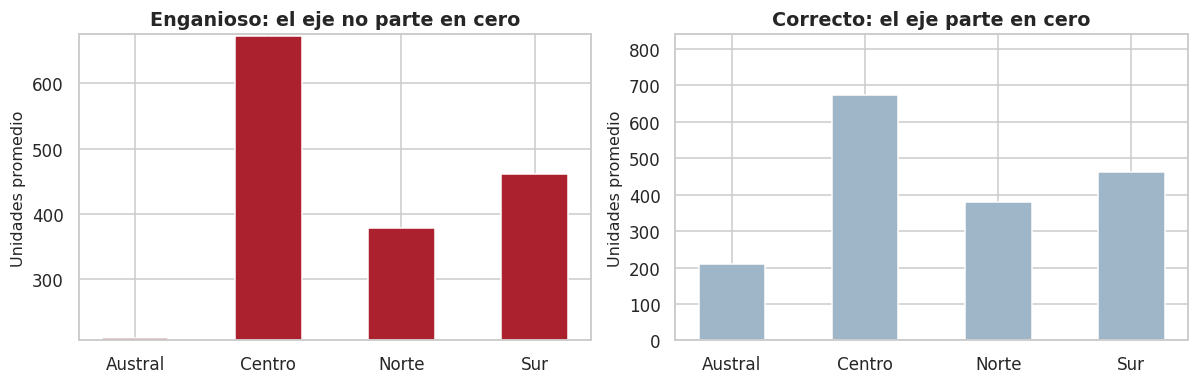

Diferencia real entre la mayor y la menor: 462 unidades (220.1 por ciento)


In [ ]:
por_region = ventas.groupby("region", observed=True)["unidades"].mean()

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.6))
ejes[0].bar(por_region.index, por_region.values, color=DESTACADO, width=0.5)
ejes[0].set_ylim(por_region.min() * 0.985, por_region.max() * 1.005)
ejes[0].set_title("Enganioso: el eje no parte en cero")

ejes[1].bar(por_region.index, por_region.values, color=NEUTRO, width=0.5)
ejes[1].set_ylim(0, por_region.max() * 1.25)
ejes[1].set_title("Correcto: el eje parte en cero")

for eje in ejes:
    eje.set_ylabel("Unidades promedio")
plt.tight_layout(); plt.show()

print(f"Diferencia real entre la mayor y la menor: "
      f"{por_region.max() - por_region.min():.0f} unidades "
      f"({(por_region.max()/por_region.min() - 1) * 100:.1f} por ciento)")

En barras, el largo codifica la magnitud: si el eje no parte en cero, el largo miente. En
gráficos de líneas la regla es distinta, porque lo representado es la variación, y ahí
recortar el eje es admisible si se declara.

## 10.2 El circular con demasiadas categorías

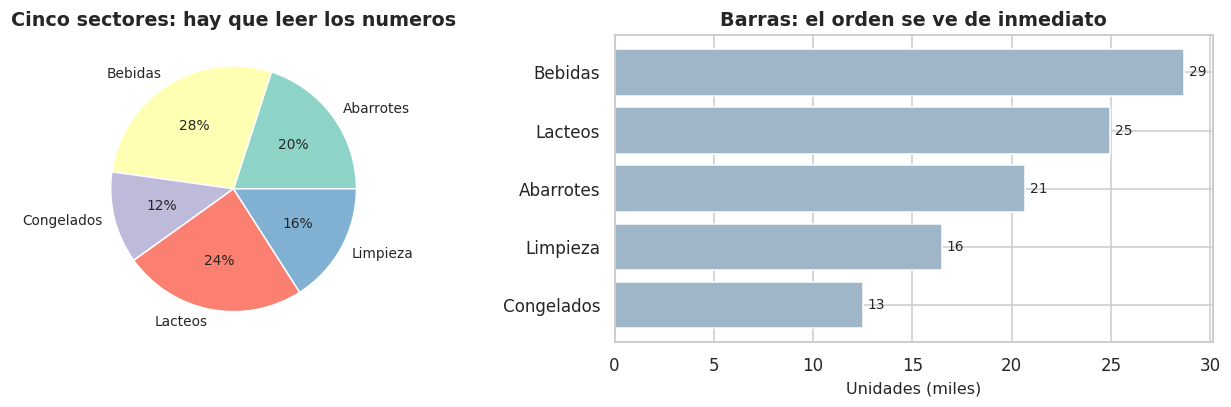

In [ ]:
frecuencias = ventas.groupby("categoria", observed=True)["unidades"].sum()

fig, ejes = plt.subplots(1, 2, figsize=(12, 3.8))
ejes[0].pie(frecuencias.values, labels=frecuencias.index, autopct="%1.0f%%",
            colors=sns.color_palette("Set3", 5), textprops={"fontsize": 9})
ejes[0].set_title("Cinco sectores: hay que leer los numeros")

orden = frecuencias.sort_values()
b = ejes[1].barh(orden.index, orden.values / 1000, color=NEUTRO)
ejes[1].bar_label(b, fmt="%.0f", padding=3, fontsize=9)
ejes[1].set_title("Barras: el orden se ve de inmediato")
ejes[1].set_xlabel("Unidades (miles)")
plt.tight_layout(); plt.show()

## 10.3 Los ejes dobles con escalas distintas

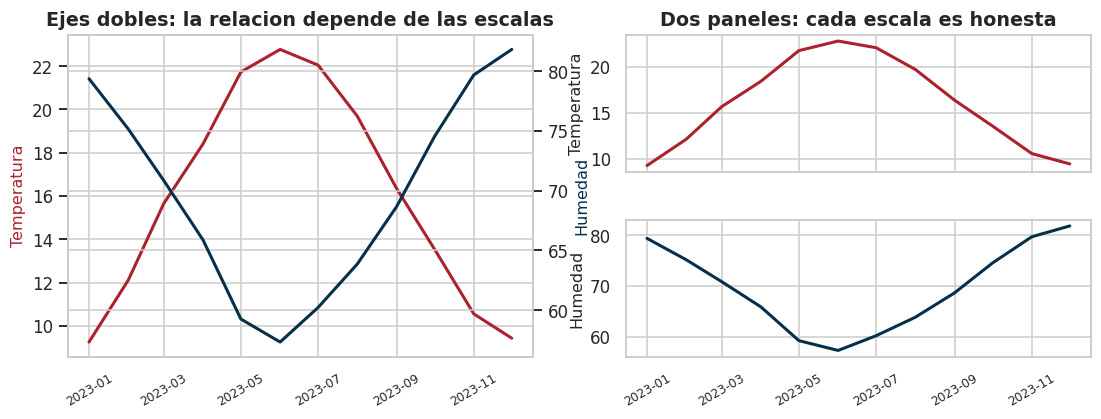

In [ ]:
mensual = clima.set_index("fecha").resample("MS").mean(numeric_only=True).head(12)

fig, ejes = plt.subplots(1, 2, figsize=(12, 3.8))

# Ejes dobles: quien hace el gráfico elige dónde se cruzan
eje_a = ejes[0]
eje_b = eje_a.twinx()
eje_a.plot(mensual.index, mensual["temperatura"], color=DESTACADO, linewidth=2)
eje_b.plot(mensual.index, mensual["humedad"], color=CONTRASTE, linewidth=2)
eje_a.set_ylabel("Temperatura", color=DESTACADO)
eje_b.set_ylabel("Humedad", color=CONTRASTE)
eje_a.set_title("Ejes dobles: la relacion depende de las escalas")
eje_a.tick_params(axis="x", rotation=30, labelsize=8)

# Alternativa: dos paneles con el mismo eje horizontal
ejes[1].remove()
sub = fig.add_gridspec(2, 2, hspace=0.35)
eje_c = fig.add_subplot(sub[0, 1])
eje_d = fig.add_subplot(sub[1, 1], sharex=eje_c)
eje_c.plot(mensual.index, mensual["temperatura"], color=DESTACADO, linewidth=2)
eje_c.set_ylabel("Temperatura"); eje_c.set_title("Dos paneles: cada escala es honesta")
eje_c.tick_params(labelbottom=False)
eje_d.plot(mensual.index, mensual["humedad"], color=CONTRASTE, linewidth=2)
eje_d.set_ylabel("Humedad"); eje_d.tick_params(axis="x", rotation=30, labelsize=8)

plt.show()

**El problema de los ejes dobles** es que quien construye el gráfico elige dónde se cruzan
las curvas, así que puede sugerir cualquier relación. Dos paneles apilados que compartan
el eje horizontal comunican lo mismo sin esa ambigüedad.

## 10.4 El orden alfabético en variables ordinales

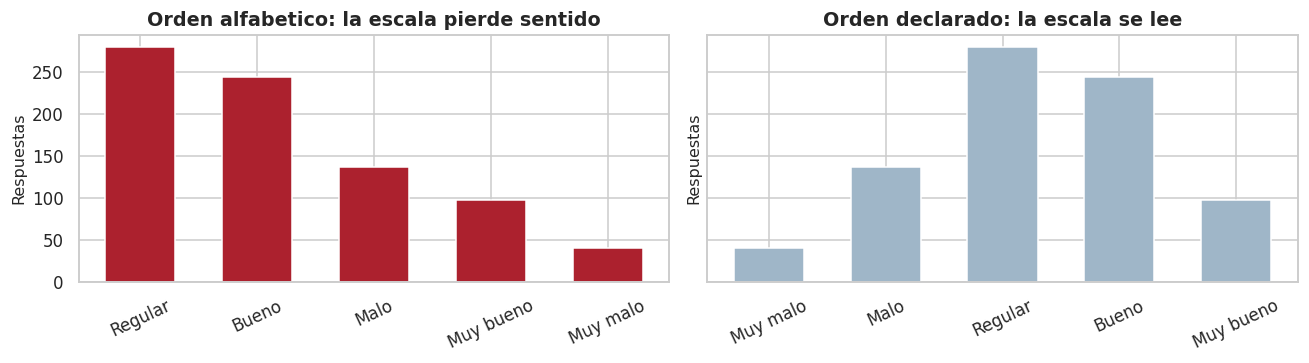

In [ ]:
sin_orden = encuesta["satisfaccion"].astype(str).value_counts()
con_orden = encuesta["satisfaccion"].value_counts().reindex(NIVELES)

fig, ejes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
ejes[0].bar(sin_orden.index, sin_orden.values, color=DESTACADO, width=0.6)
ejes[0].set_title("Orden alfabetico: la escala pierde sentido")
ejes[1].bar(con_orden.index, con_orden.values, color=NEUTRO, width=0.6)
ejes[1].set_title("Orden declarado: la escala se lee")

for eje in ejes:
    eje.tick_params(axis="x", rotation=25)
    eje.set_ylabel("Respuestas")
plt.tight_layout(); plt.show()

Este error aparece solo si la variable es ordinal, y es de los más frecuentes. Se evita
declarando el orden con `pd.Categorical(..., ordered=True)` en la preparación, no al
graficar.

---
# XI. Terminar y exportar la figura

El gráfico está dibujado; falta lo que lo convierte en una figura de informe.

## 11.1 Una función que aplica el rotulado obligatorio

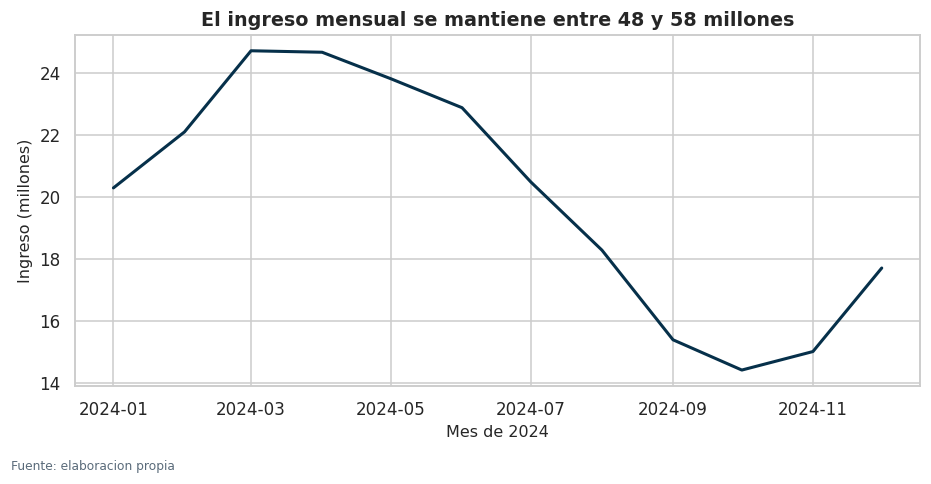

In [ ]:
def rotular(fig, eje, titulo, x, y, fuente="elaboracion propia"):
    """Aplica el rotulado que un informe tecnico exige a cada figura.

    Centralizarlo evita que alguna figura quede sin titulo, sin unidades o
    sin fuente, que es lo que las rubricas penalizan.
    """
    eje.set_title(titulo)
    eje.set_xlabel(x)
    eje.set_ylabel(y)
    fig.text(0.01, -0.03, f"Fuente: {fuente}", fontsize=8, color="#5A6B7A")
    return eje


fig, eje = plt.subplots(figsize=(8.5, 4.2))
serie = ventas.groupby("mes", observed=True)["ingreso"].sum().div(1e6)
eje.plot(serie.index, serie.values, linewidth=2, color=CONTRASTE)

# Formato de miles en el eje vertical
eje.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))

rotular(fig, eje,
        "El ingreso mensual se mantiene entre 48 y 58 millones",
        "Mes de 2024", "Ingreso (millones)")
plt.tight_layout(); plt.show()

## 11.2 Color con función y accesibilidad

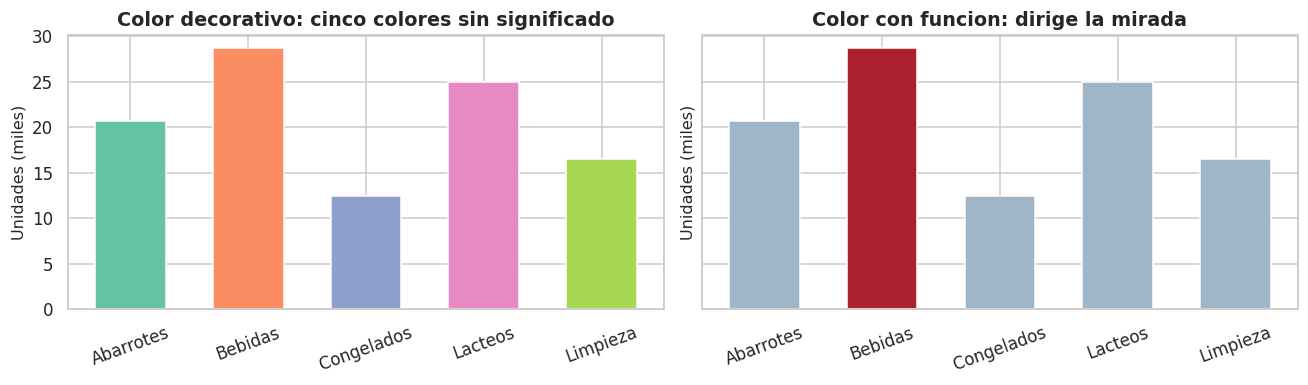

Paletas seguras para daltonismo: 'colorblind', 'viridis', 'cividis'
Cerca del 8 por ciento de los hombres no distingue bien rojo y verde:
el color nunca debe ser el unico canal que transmite informacion.


In [ ]:
por_categoria = ventas.groupby("categoria", observed=True)["unidades"].sum().div(1000)

fig, ejes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
ejes[0].bar(por_categoria.index, por_categoria.values,
            color=sns.color_palette("Set2", len(por_categoria)), width=0.6)
ejes[0].set_title("Color decorativo: cinco colores sin significado")

destacar = por_categoria == por_categoria.max()
ejes[1].bar(por_categoria.index, por_categoria.values,
            color=[DESTACADO if d else NEUTRO for d in destacar], width=0.6)
ejes[1].set_title("Color con funcion: dirige la mirada")

for eje in ejes:
    eje.tick_params(axis="x", rotation=20)
    eje.set_ylabel("Unidades (miles)")
plt.tight_layout(); plt.show()

print("Paletas seguras para daltonismo: 'colorblind', 'viridis', 'cividis'")
print("Cerca del 8 por ciento de los hombres no distingue bien rojo y verde:")
print("el color nunca debe ser el unico canal que transmite informacion.")

## 11.3 Exportar para el informe

In [ ]:
os.makedirs("figuras", exist_ok=True)

fig, eje = plt.subplots(figsize=(8, 4.2))
por_region = ventas.groupby("region", observed=True)["unidades"].sum().div(1000)
barras = eje.bar(por_region.index, por_region.values,
                 color=[DESTACADO if v == por_region.max() else NEUTRO
                        for v in por_region], width=0.6)
eje.bar_label(barras, fmt="%.0f", padding=3)
rotular(fig, eje, "Figura 1. La region Centro concentra el mayor volumen",
        "Region", "Unidades (miles)")

# bbox_inches recorta el espacio sobrante y evita que se corte el pie
fig.savefig("figuras/figura_1_volumen_por_region.png", dpi=200, bbox_inches="tight")
plt.close(fig)

tam = os.path.getsize("figuras/figura_1_volumen_por_region.png") / 1024
print(f"Guardada: figuras/figura_1_volumen_por_region.png ({tam:.0f} KB)")
print("\nExportar desde el notebook, y no capturar la pantalla, permite:")
print("  1. controlar la resolucion con dpi")
print("  2. versionar la figura en el repositorio")
print("  3. regenerarla toda si cambian los datos")

Guardada: figuras/figura_1_volumen_por_region.png (58 KB)

Exportar desde el notebook, y no capturar la pantalla, permite:
  1. controlar la resolucion con dpi
  2. versionar la figura en el repositorio
  3. regenerarla toda si cambian los datos


---
# XII. Su turno

Tres ejercicios con **su propio conjunto**. No requieren copiar código de este cuaderno:
requieren decidir.

## Ejercicio 1 · Clasifiquen sus preguntas

Para cada objetivo de su proyecto, identifiquen a qué familia pertenece: comparación,
distribución, relación, evolución, composición o panorama. Esa clasificación decide el
gráfico antes de escribir una línea de código.

In [ ]:
MIS_PREGUNTAS = {
    1: {"pregunta": "TODO: la pregunta que quiere responder",
        "familia": "TODO: comparacion / distribucion / relacion / evolucion / composicion",
        "grafico": "TODO: el tipo elegido y por que"},
    2: {"pregunta": "TODO", "familia": "TODO", "grafico": "TODO"},
    3: {"pregunta": "TODO", "familia": "TODO", "grafico": "TODO"},
}

for n, d in MIS_PREGUNTAS.items():
    print(f"{n}. {d['pregunta']}")
    print(f"   Familia: {d['familia']}")
    print(f"   Grafico: {d['grafico']}\n")

1. TODO: la pregunta que quiere responder
   Familia: TODO: comparacion / distribucion / relacion / evolucion / composicion
   Grafico: TODO: el tipo elegido y por que

2. TODO
   Familia: TODO
   Grafico: TODO

3. TODO
   Familia: TODO
   Grafico: TODO



## Ejercicio 2 · Construyan y comparen

Elijan una de sus preguntas y constrúyanla con **dos tipos de gráfico distintos**. Después
decidan cuál comunica mejor y escriban por qué. Esa justificación es material directo para
el informe.

In [ ]:
# TODO: carguen su conjunto
# mi_df = pd.read_csv("ruta/a/su/archivo.csv")

# TODO: version A de la figura

# TODO: version B de la misma pregunta, con otro tipo de grafico

# TODO: en una celda de texto, expliquen cual eligen y por que

## Ejercicio 3 · Terminen la figura

Tomen la versión que eligieron y apliquen todo lo del apartado XI: título que comunica el
hallazgo, ejes con unidad, color con función, fuente al pie y exportación.

Y escriban debajo las cuatro frases: qué muestra, qué infiero, qué límite tiene y cómo
aporta al relato.

---
# Cierre

## Lo que se llevan

| Idea | Por qué importa |
|---|---|
| Cada canal visual tiene una precisión distinta | Explica por qué barras superan a circular |
| El gráfico se elige por la forma de la pregunta | Evita decidir por gusto |
| El título comunica el hallazgo, no el tema | Es lo único que el lector retiene de cada figura |
| El color señala, no decora | Dirige la mirada al hallazgo |
| El eje de barras parte en cero | El largo codifica la magnitud |
| Las variables ordinales conservan su orden | El orden alfabético destruye la escala |
| Los paneles sirven para estratificar | Permiten detectar variables de confusión |
| Cada figura lleva título, ejes con unidad, leyenda y fuente | Es lo que las rúbricas evalúan |

## Las familias, en una línea cada una

- **Comparación.** Barras, paletas, divergentes. Cuánto tiene cada grupo.
- **Distribución.** Histograma, densidad, acumulada, caja, violín, enjambre. Cómo se reparten los valores.
- **Relación.** Dispersión, tendencia, burbujas, hexágonos, conjunto. Si dos variables se mueven juntas.
- **Evolución.** Líneas, áreas, pendiente. Cómo cambia en el tiempo.
- **Composición.** Apiladas, divergentes de escala, circular. De qué partes se compone un total.
- **Panorama.** Mapas de calor, matriz de dispersión. Qué estructura tiene el conjunto.

---

*Parte práctica de la Semana 3 · Fase 4 · MCDI500 · Magíster en Ciencia de Datos e
Inteligencia Artificial · Universidad Andrés Bello*